<a href="https://colab.research.google.com/github/JulianNguyen05/xiangqi-sorting-jetmax/blob/main/training/build_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BƯỚC 1 — XÂY DỰNG BỘ DỮ LIỆU NHẬN DIỆN QUÂN CỜ TƯỚNG

**Đề tài:** Robot JetMax nhận diện và sắp xếp quân cờ tướng bằng học sâu
**Notebook này:** chuẩn bị dữ liệu → đầu ra là `merged_v1.zip`, dùng cho notebook `train_yolo11.ipynb`.

### Bài toán
Camera của robot nhìn từ trên xuống, mô hình phải trả về **vị trí (bounding box)** và **loại quân** của mọi quân cờ trong ảnh để cánh tay robot gắp đúng quân, đặt đúng ô. Có **14 lớp** = 7 loại quân × 2 màu.

| Quân (tiếng Việt) | Lớp | Chữ trên quân đỏ | Chữ trên quân đen |
|---|---|---|---|
| Tướng | `king` | 帥 | 將 |
| Sĩ | `advisor` | 仕 | 士 |
| Tượng | `bishop` | 相 | 象 |
| Xe | `rook` | 俥 | 車 |
| Mã | `knight` | 傌 | 馬 |
| Pháo | `cannon` | 炮 | 砲 / 包 |
| Tốt | `pawn` | 兵 | 卒 |

> 💡 **Điểm khó:** các quân giống hệt nhau về hình dạng (đều là đĩa tròn), chỉ khác **chữ Hán khắc trên mặt** và **màu chữ**. Một số cặp chữ đỏ/đen khác nhau hoàn toàn (帥/將, 兵/卒), một số gần giống (俥/車, 傌/馬). Vì vậy mô hình phải "đọc" được nét chữ, không chỉ nhận ra hình tròn.

## Quy trình xử lý dữ liệu (tổng quan)

| # | Bước | Mục đích | Kết quả |
|---|---|---|---|
| 1 | Tải 4 bộ dataset từ Roboflow Universe | Có đủ dữ liệu đa dạng mà không phải tự gán nhãn từ đầu | 4 thư mục định dạng YOLO |
| 2 | Kiểm tra lớp, số ảnh, lỗi nhãn | Mỗi bộ đặt tên lớp khác nhau, có bộ dùng polygon/keypoint | Biết cần sửa gì |
| 3 | Chuẩn hoá về 14 lớp + đổi polygon/pose → bbox | Đưa 4 bộ về **cùng một chuẩn** | `/content/pool` (6 808 ảnh) |
| 4 | Gom ảnh trùng (pHash + union-find) | Tránh **rò rỉ dữ liệu** giữa train và test | 4 265 nhóm ảnh |
| 5 | Chia train/val/test theo nhóm (≈80/10/10) | Tập test khách quan, tỷ lệ các bộ đồng đều | 5 469 / 675 / 664 ảnh |
| 6 | Kiểm tra bằng mắt + kiểm tra 1 ảnh test | Chắc chắn nhãn đúng trước khi train | `merged_v1.zip` |

Sơ đồ bên dưới minh hoạ luồng dữ liệu (cell vẽ hình, không phụ thuộc dữ liệu).

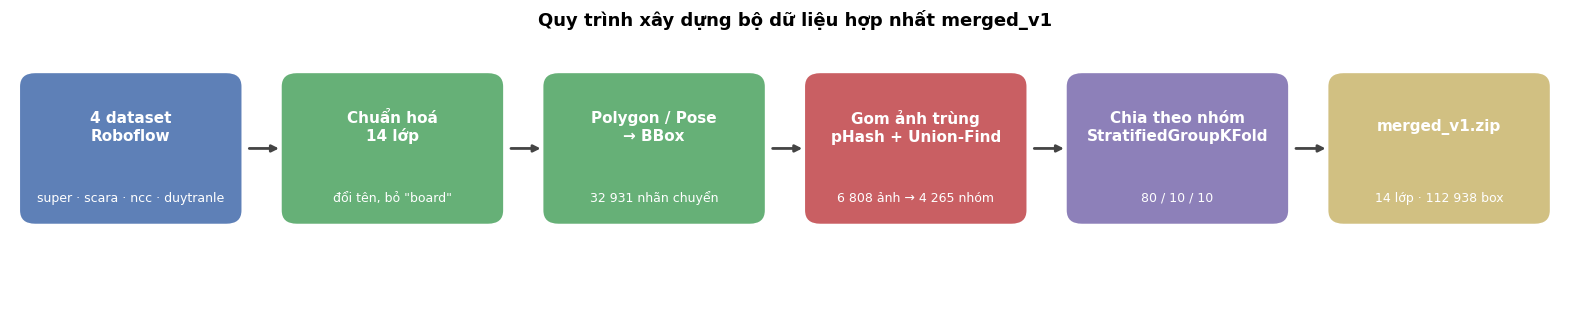

In [5]:
# ── Sơ đồ quy trình xây dựng dataset (chỉ để minh hoạ, không xử lý dữ liệu)
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

steps = [
    ('4 dataset\nRoboflow', 'super · scara · ncc · duytranle', '#4C72B0'),
    ('Chuẩn hoá\n14 lớp', 'đổi tên, bỏ "board"', '#55A868'),
    ('Polygon / Pose\n→ BBox', '32 931 nhãn chuyển', '#55A868'),
    ('Gom ảnh trùng\npHash + Union-Find', '6 808 ảnh → 4 265 nhóm', '#C44E52'),
    ('Chia theo nhóm\nStratifiedGroupKFold', '80 / 10 / 10', '#8172B2'),
    ('merged_v1.zip', '14 lớp · 112 938 box', '#CCB974'),
]
fig, ax = plt.subplots(figsize=(16, 3.2))
ax.set_xlim(0, len(steps) * 2.6); ax.set_ylim(0, 3); ax.axis('off')
for i, (title, sub, color) in enumerate(steps):
    x = i * 2.6 + 0.15
    ax.add_patch(FancyBboxPatch((x, 0.9), 2.1, 1.6, boxstyle='round,pad=0.05,rounding_size=0.15',
                                fc=color, ec='none', alpha=0.9))
    ax.text(x + 1.05, 1.95, title, ha='center', va='center', color='white', fontsize=11, fontweight='bold')
    ax.text(x + 1.05, 1.15, sub, ha='center', va='center', color='white', fontsize=9)
    if i < len(steps) - 1:
        ax.annotate('', xy=(x + 2.55, 1.7), xytext=(x + 2.2, 1.7),
                    arrowprops=dict(arrowstyle='-|>', color='#444', lw=2))
ax.set_title('Quy trình xây dựng bộ dữ liệu hợp nhất merged_v1', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

## Tại sao chọn 4 bộ dữ liệu này?

**1. Không có sẵn một bộ dữ liệu chuẩn, đủ lớn cho cờ tướng.** Khác với COCO hay ImageNet, cờ tướng chỉ có các bộ nhỏ do cộng đồng đóng góp. Tự chụp và gán nhãn ~100 000 box là không khả thi trong thời gian đồ án, nên chọn cách **gộp nhiều bộ công khai** trên Roboflow Universe.

**2. Tiêu chí lựa chọn:**

| Tiêu chí | Lý do |
|---|---|
| Có đủ **14 lớp** (7 loại × 2 màu) | Đúng yêu cầu bài toán; bộ thiếu lớp sẽ làm lệch dữ liệu |
| Nhãn dạng **bbox / polygon / keypoint** đổi được về bbox | Dùng chung cho YOLO detection |
| Tải được bằng API Roboflow, có **phiên bản cố định** | Tái lập được kết quả (phiên bản ghi vào `versions_used.json`) |
| **Khác nhau** về bộ quân, góc chụp, ánh sáng, nền | Mô hình không học "thuộc lòng" một bộ quân hay một camera |

**3. Vai trò của từng bộ:**

| Bộ | Đặc điểm (theo nội dung và tên dự án) | Đóng góp |
|---|---|---|
| `super` | Bộ tổng hợp lớn, có lớp `board` và một phần nhãn polygon | Số lượng lớn, đa dạng |
| `scara` | Dữ liệu cho robot SCARA chơi cờ: bàn cờ giữa trận, từng quân rời, bàn trống | **Bối cảnh gần với robot JetMax nhất** |
| `new_chinese_chess` | Bộ nhỏ, ít box mỗi ảnh | Thêm kiểu quân / nền khác |
| `duytranle` | Nhãn dạng keypoint (pose), nhiều quân trên bàn | Thêm ~32 000 box sau khi chuyển về bbox |

**4. Hạn chế đã biết:** dữ liệu vẫn là ảnh công khai, chưa phải ảnh chụp từ chính camera robot. Thư mục `own_images/` được tạo sẵn để bổ sung ảnh tự chụp và fine-tune thêm nếu cần.

---
# 1. Chuẩn bị môi trường
## 1.1 Mount Drive và tạo thư mục
Colab xoá sạch ổ đĩa sau mỗi phiên, nên dữ liệu lâu dài (zip gốc, dataset hợp nhất, kết quả train) được lưu ở **Google Drive**; bản giải nén để đọc nhanh thì đặt trên ổ của máy Colab (`/content`).

In [6]:
# ── Kết nối Google Drive để lưu dữ liệu lâu dài (Colab xoá ổ đĩa sau mỗi phiên)
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = '/content/drive/MyDrive/datn'   # thư mục gốc của đồ án trên Drive
RAW_DRIVE = f'{BASE}/raw'          # bản nén .zip của từng bộ (lưu lâu dài)
RAW_LOCAL = '/content/raw'         # bản giải nén trên máy Colab (đọc nhanh)
# raw: dữ liệu gốc | merged: dataset hợp nhất | runs: kết quả train | own_images: ảnh tự chụp (dự phòng)
for d in ['raw', 'merged', 'runs', 'own_images']:
    os.makedirs(f'{BASE}/{d}', exist_ok=True)
os.makedirs(RAW_LOCAL, exist_ok=True)
print('OK:', BASE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK: /content/drive/MyDrive/datn


## 1.2 Cài thư viện
- `roboflow`: tải dataset bằng API
- `imagehash`: tính *perceptual hash* để tìm ảnh trùng (bước 4)
- `pyyaml`: đọc/ghi file cấu hình `data.yaml` của YOLO

In [7]:
# roboflow: tải dataset | imagehash: tìm ảnh trùng | pyyaml: đọc/ghi data.yaml
!pip install -q roboflow imagehash pyyaml

## 1.3 Lấy API key Roboflow
API key được lưu trong **Colab Secrets** (biểu tượng 🔑 bên trái) với tên `ROBOFLOW_API_KEY`, không ghi thẳng vào notebook để tránh lộ khoá khi chia sẻ.

In [8]:
from google.colab import userdata
from roboflow import Roboflow

# ⚠ Lấy key từ Colab Secrets, KHÔNG viết key trực tiếp vào code
API_KEY = userdata.get('ROBOFLOW_API_KEY')
rf = Roboflow(api_key=API_KEY)
print('Đã kết nối Roboflow')

Đã kết nối Roboflow


---
# 2. Tải dữ liệu

## Khai báo 4 bộ dataset
Danh sách 4 dataset trên Roboflow Universe.

| Tên ngắn | Link |
|---|---|
| super | https://universe.roboflow.com/312s-workspace/xiangqi-super-dataset |
| scara | https://universe.roboflow.com/312s-workspace/xiangqi-scara-yolo26 |
| new_chinese_chess | https://universe.roboflow.com/quoc-rnmzr/new-chinese-chess-ayph4/dataset/1 |
| duytranle | https://universe.roboflow.com/duytranle/xiangqi-ubjij/dataset/18 |

In [9]:
# Mỗi bộ: workspace + project trên Roboflow, version=None nghĩa là lấy phiên bản mới nhất
DATASETS = {
    'super':             {'workspace': '312s-workspace', 'project': 'xiangqi-super-dataset',   'version': None},
    'scara':             {'workspace': '312s-workspace', 'project': 'xiangqi-scara-yolo26',    'version': None},
    'new_chinese_chess': {'workspace': 'quoc-rnmzr',     'project': 'new-chinese-chess-ayph4', 'version': 1},
    'duytranle':         {'workspace': 'duytranle',      'project': 'xiangqi-ubjij',           'version': 18,
                          'format': 'yolov8'},   # dự án keypoint không hỗ trợ yolov11
}

### Tải về, giải nén và sao lưu lên Drive
Với mỗi bộ: (1) đã có trên Colab thì bỏ qua; (2) đã có file .zip trên Drive thì giải nén; (3) chưa có thì tải từ Roboflow (định dạng yolov11) rồi nén lưu lên Drive. Phiên bản đã tải được ghi vào versions_used.json để đưa vào báo cáo.

In [10]:
import shutil, json

def latest_version(project):
    # Lấy số phiên bản lớn nhất của một project trên Roboflow
    vs = project.versions()
    return max(int(str(v.version).split('/')[-1]) for v in vs)

# Ghi lại phiên bản đã dùng -> tái lập được kết quả, đưa vào báo cáo
VERSIONS_FILE = f'{BASE}/raw/versions_used.json'
versions_used = json.load(open(VERSIONS_FILE)) if os.path.exists(VERSIONS_FILE) else {}
paths = {}

for name, cfg in DATASETS.items():
    out_dir  = f'{RAW_LOCAL}/{name}'
    zip_base = f'{RAW_DRIVE}/{name}'

    # Ưu tiên: (1) đã giải nén trên Colab -> (2) có zip trên Drive -> (3) tải mới từ Roboflow
    if os.path.isdir(out_dir) and os.listdir(out_dir):
        print(f'[{name}] đã có trên Colab, bỏ qua')
    elif os.path.exists(zip_base + '.zip'):
        print(f'[{name}] giải nén từ Drive...')
        shutil.unpack_archive(zip_base + '.zip', out_dir)
    else:
        print(f'[{name}] tải từ Roboflow...')
        project = rf.workspace(cfg['workspace']).project(cfg['project'])
        ver = cfg['version'] or latest_version(project)
        fmt = cfg.get('format', 'yolov11')
        project.version(ver).download(fmt, location=out_dir)
        shutil.make_archive(zip_base, 'zip', out_dir)          # sao lưu lên Drive
        versions_used[name] = {**cfg, 'version': ver, 'format': fmt}
        with open(VERSIONS_FILE, 'w') as f:
            json.dump(versions_used, f, indent=2, ensure_ascii=False)
        print(f'[{name}] đã tải version {ver} (định dạng {fmt}) và lưu lên Drive')

    paths[name] = out_dir

print('Xong:', list(paths))

[super] tải từ Roboflow...
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/raw/super in yolov11:: 100%|██████████| 8915/8915 [00:02<00:00, 3228.17it/s]


[super] đã tải version 1 (định dạng yolov11) và lưu lên Drive
[scara] giải nén từ Drive...
[new_chinese_chess] giải nén từ Drive...
[duytranle] giải nén từ Drive...
Xong: ['super', 'scara', 'new_chinese_chess', 'duytranle']


---
# 3. Khảo sát dữ liệu thô

### Kiểm tra tên lớp và số ảnh của từng bộ
In danh sách lớp (names trong data.yaml) và số ảnh mỗi tập. Với mỗi bộ: in tên lớp, số ảnh (và số ảnh gốc ước lượng) mỗi tập, bảng số box theo lớp ở từng tập, và các lỗi nhãn.

> **Đọc kết quả ô dưới:**
> - Định dạng nhãn YOLO: mỗi dòng `class x_center y_center width height`, toạ độ **chuẩn hoá về [0, 1]** theo kích thước ảnh.
> - "~ảnh gốc ước lượng": Roboflow đặt tên ảnh augment dạng `<tên gốc>.rf.<hash>.jpg`. Ví dụ `super/train` có 4 107 ảnh nhưng chỉ ~1 779 ảnh gốc → **mỗi ảnh gốc có khoảng 2–3 bản augment**. Đây là lý do phải gom nhóm ở bước 5.
> - Các bộ **đặt tên lớp khác nhau** (`black_advisor` / `Black_Guard` / ...) và có lớp thừa (`board`, `None`) → phải chuẩn hoá.

In [11]:
import yaml, glob, os
import pandas as pd
from collections import Counter

SPLITS = ['train', 'valid', 'test']
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
MIN_BOX_WARN = 300          # lớp có ít box hơn mức này sẽ bị cảnh báo
pd.set_option('display.width', 220)

def load_names(yaml_path):
    # Đọc danh sách tên lớp trong data.yaml (có bộ ghi dạng list, có bộ ghi dạng dict)
    with open(yaml_path, encoding='utf-8') as f:
        names = yaml.safe_load(f)['names']
    if isinstance(names, dict):
        names = [names[k] for k in sorted(names)]
    return names

def source_id(filename):
    # Roboflow: <tên gốc>.rf.<hash>.jpg -> bản augment cùng một ảnh gốc
    return filename.split('.rf.')[0]

reports = {}
for name, p in paths.items():
    print('=' * 80)
    print(name.upper())
    yaml_files = glob.glob(f'{p}/**/data.yaml', recursive=True)
    if not yaml_files:
        print('  Không thấy data.yaml')
        continue
    root = os.path.dirname(yaml_files[0])
    names = load_names(yaml_files[0])
    print(f'  Số lớp: {len(names)}')
    print(f'  Tên lớp: {names}')

    box = {s: Counter() for s in SPLITS}      # số box theo lớp
    img_with = Counter()                      # số ảnh có chứa lớp (cả 3 tập)
    problems = Counter()                      # đếm các loại lỗi nhãn

    for s in SPLITS:
        img_files = [f for f in glob.glob(f'{root}/{s}/images/*')
                     if f.lower().endswith(IMG_EXT)]
        n_src = len({source_id(os.path.basename(f)) for f in img_files})
        print(f'  {s:6s}: {len(img_files):5d} ảnh  (~{n_src} ảnh gốc ước lượng)')

        # Ảnh và file nhãn phải khớp 1-1 theo tên
        lbl_files = glob.glob(f'{root}/{s}/labels/*.txt')
        img_stems = {os.path.splitext(os.path.basename(f))[0] for f in img_files}
        lbl_stems = {os.path.splitext(os.path.basename(f))[0] for f in lbl_files}
        problems['ảnh không có file nhãn'] += len(img_stems - lbl_stems)
        problems['file nhãn không có ảnh'] += len(lbl_stems - img_stems)

        for lf in lbl_files:
            with open(lf) as f:
                lines = [l.split() for l in f if l.strip()]
            if not lines:
                problems['file nhãn rỗng'] += 1
            seen = set()
            for parts in lines:
                # Dòng bbox chuẩn có đúng 5 giá trị; nhiều hơn là polygon hoặc keypoint
                if len(parts) != 5:
                    problems['dòng nhãn không phải bbox (5 giá trị)'] += 1
                    continue
                try:
                    cid = int(parts[0])
                    x, y, w, h = map(float, parts[1:])
                except ValueError:
                    problems['dòng nhãn sai định dạng'] += 1
                    continue
                if not (0 <= cid < len(names)):
                    problems['id lớp ngoài phạm vi'] += 1
                    continue
                if w <= 0 or h <= 0:
                    problems['box có w hoặc h <= 0'] += 1
                if x - w/2 < -0.01 or y - h/2 < -0.01 or x + w/2 > 1.01 or y + h/2 > 1.01:
                    problems['box lệch ra ngoài khung ảnh'] += 1
                box[s][names[cid]] += 1
                seen.add(names[cid])
            for c in seen:
                img_with[c] += 1

    df = pd.DataFrame({f'{s}_box': pd.Series(box[s]) for s in SPLITS}).reindex(names).fillna(0).astype(int)
    df['tong_box'] = df.sum(axis=1)
    df['tong_anh_co_lop'] = pd.Series(img_with).reindex(names).fillna(0).astype(int)
    reports[name] = df

    print('\n  Số box theo lớp:')
    print(df.to_string())
    print(f"\n  Tổng box: {df['tong_box'].sum()}")
    weak = df[df['tong_box'] < MIN_BOX_WARN].index.tolist()
    if weak:
        print(f'  ⚠ Lớp ít hơn {MIN_BOX_WARN} box: {weak}')
    if problems:
        print('  ⚠ Vấn đề phát hiện:')
        for k, v in problems.items():
            print(f'     - {k}: {v}')
    else:
        print('  Không phát hiện lỗi nhãn cơ bản.')

SUPER
  Số lớp: 15
  Tên lớp: ['black_advisor', 'black_bishop', 'black_cannon', 'black_king', 'black_knight', 'black_pawn', 'black_rook', 'board', 'red_advisor', 'red_bishop', 'red_cannon', 'red_king', 'red_knight', 'red_pawn', 'red_rook']
  train :  4107 ảnh  (~1779 ảnh gốc ước lượng)
  valid :   291 ảnh  (~289 ảnh gốc ước lượng)
  test  :    57 ảnh  (~57 ảnh gốc ước lượng)

  Số box theo lớp:
               train_box  valid_box  test_box  tong_box  tong_anh_co_lop
black_advisor       2406        254       101      2761             1461
black_bishop        2108        239        96      2443             1354
black_cannon        1159        112        55      1326              889
black_king          1316        142        52      1510             1504
black_knight        1566        173        63      1802             1256
black_pawn          4387        493       174      5054             1451
black_rook          2310        267        83      2660             1368
board             

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


### 📊 Biểu đồ: số ảnh thô của từng bộ theo tập gốc
Cho thấy quy mô từng bộ và cách các tác giả gốc chia tập: tập test gốc của nhiều bộ rất nhỏ (ví dụ `super` chỉ 57 ảnh test), không đủ để đánh giá khách quan → **cần chia lại**.

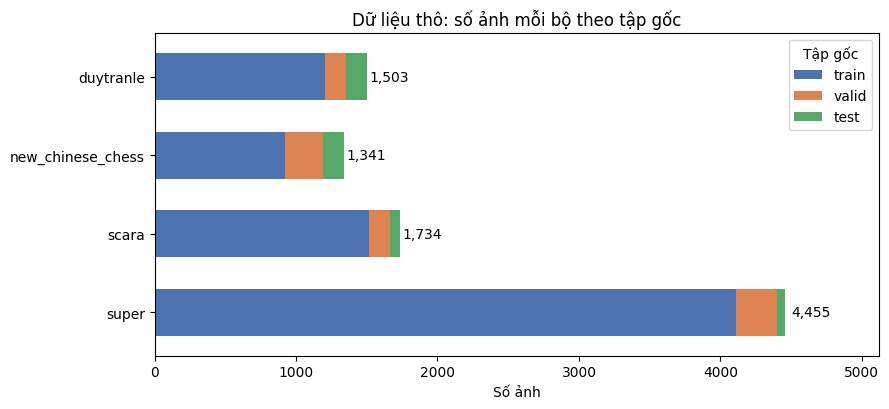

                   train  valid  test  tong
super               4107    291    57  4455
scara               1518    144    72  1734
new_chinese_chess    924    268   149  1341
duytranle           1202    150   151  1503


In [12]:
import matplotlib.pyplot as plt

# Đếm số ảnh thô theo bộ và tập gốc (train/valid/test do tác giả dataset chia)
raw_counts = {}
for name, p in paths.items():
    root = os.path.dirname(glob.glob(f'{p}/**/data.yaml', recursive=True)[0])
    raw_counts[name] = {s: sum(f.lower().endswith(IMG_EXT) for f in glob.glob(f'{root}/{s}/images/*'))
                        for s in SPLITS}
raw_df = pd.DataFrame(raw_counts).T[SPLITS]

fig, ax = plt.subplots(figsize=(9, 4.2))
raw_df.plot.barh(stacked=True, ax=ax, color=['#4C72B0', '#DD8452', '#55A868'], width=0.6)
for i, total in enumerate(raw_df.sum(axis=1)):
    ax.text(total * 1.01, i, f'{total:,}', va='center', fontsize=10)
ax.set_xlabel('Số ảnh'); ax.set_title('Dữ liệu thô: số ảnh mỗi bộ theo tập gốc')
ax.set_xlim(0, raw_df.sum(axis=1).max() * 1.15); ax.legend(title='Tập gốc')
plt.tight_layout(); plt.show()
print(raw_df.assign(tong=raw_df.sum(axis=1)))

### Chẩn đoán dòng nhãn không phải bbox
Với mỗi bộ: đếm dòng 5 giá trị (bbox chuẩn) và các dòng khác, gom theo (lớp, số giá trị mỗi dòng), in kèm một dòng mẫu. Dùng để biết dòng lạ là polygon (segmentation) hay pose (keypoint) và thuộc lớp nào.

In [13]:
from collections import Counter

# Với mỗi bộ: đếm dòng bbox chuẩn (5 giá trị) và gom các dòng "lạ" theo (lớp, số giá trị/dòng)
for name, p in paths.items():
    yf = glob.glob(f'{p}/**/data.yaml', recursive=True)[0]
    root = os.path.dirname(yf)
    names = load_names(yf)
    odd, sample, ok = Counter(), {}, 0
    for lf in glob.glob(f'{root}/*/labels/*.txt'):
        for line in open(lf):
            parts = line.split()
            if not parts:
                continue
            if len(parts) == 5:
                ok += 1
                continue
            key = (names[int(parts[0])], len(parts))
            odd[key] += 1
            sample.setdefault(key, ' '.join(parts[:12]))   # giữ 1 dòng mẫu để xem
    print('=' * 70)
    print(f'{name} | dòng 5 giá trị: {ok} | dòng khác: {sum(odd.values())}')
    for (cls, n), c in odd.most_common(6):
        print(f'  lớp={cls:15s} số giá trị/dòng={n:3d}  số dòng={c}')
        print('     mẫu:', sample[(cls, n)])

super | dòng 5 giá trị: 34886 | dòng khác: 3551
  lớp=board           số giá trị/dòng= 11  số dòng=2137
     mẫu: 7 0.0897015625 0.9431234375 0.9368765625 0.9431234375 0.9368765625 0.0599796875 0.0897015625 0.0599796875 0.0897015625 0.9431234375
  lớp=red_pawn        số giá trị/dòng= 41  số dòng=80
     mẫu: 13 0.034375 0.4 0.021875 0.409375 0.0109375 0.4296875 0.009375 0.4421875 0.0125 0.4546875 0.01875
  lớp=red_pawn        số giá trị/dòng= 39  số dòng=42
     mẫu: 13 0.815625 0.49375 0.8046875 0.496875 0.7875 0.509375 0.778125 0.53125 0.778125 0.54375 0.7859375
  lớp=black_pawn      số giá trị/dòng= 43  số dòng=42
     mẫu: 5 0.25 0.3046875 0.2359375 0.31875 0.23125 0.33125 0.23125 0.3515625 0.234375 0.3625 0.240625
  lớp=red_cannon      số giá trị/dòng= 43  số dòng=40
     mẫu: 10 0.58125 0.4 0.575 0.4046875 0.5671875 0.4125 0.5671875 0.415625 0.559375 0.4265625 0.5578125
  lớp=red_pawn        số giá trị/dòng= 47  số dòng=40
     mẫu: 13 0.578125 0.6 0.5671875 0.609375 0.5671875 0.

> **Kết luận từ ô trên:**
> - `super`: có 2 loại dòng lạ: (1) lớp `board` dạng polygon 4 đỉnh (11 giá trị) → **bỏ**, vì không cần nhận diện bàn cờ; (2) một số quân được gán nhãn **polygon** (nhiều đỉnh) → đổi thành bbox bao ngoài.
> - `duytranle`: **toàn bộ** là nhãn **pose** (`lớp x y w h` + các keypoint) → chỉ lấy 4 giá trị đầu là bbox.
> - `scara`, `new_chinese_chess`: đã là bbox chuẩn.
>
> Công thức đổi polygon $(x_1,y_1,\dots,x_n,y_n)$ → bbox:
> $$x_c = \tfrac{\min x_i + \max x_i}{2},\quad y_c = \tfrac{\min y_i + \max y_i}{2},\quad w = \max x_i - \min x_i,\quad h = \max y_i - \min y_i$$

### 🖼 Minh hoạ: polygon / pose được đổi thành bbox như thế nào
Ảnh trái: một ảnh của `super` có nhãn polygon (đường vàng) và bbox suy ra (khung đỏ đứt nét).
Ảnh phải: một ảnh của `duytranle` có nhãn pose: bbox (xanh) được giữ lại, các keypoint (chấm) bị bỏ.

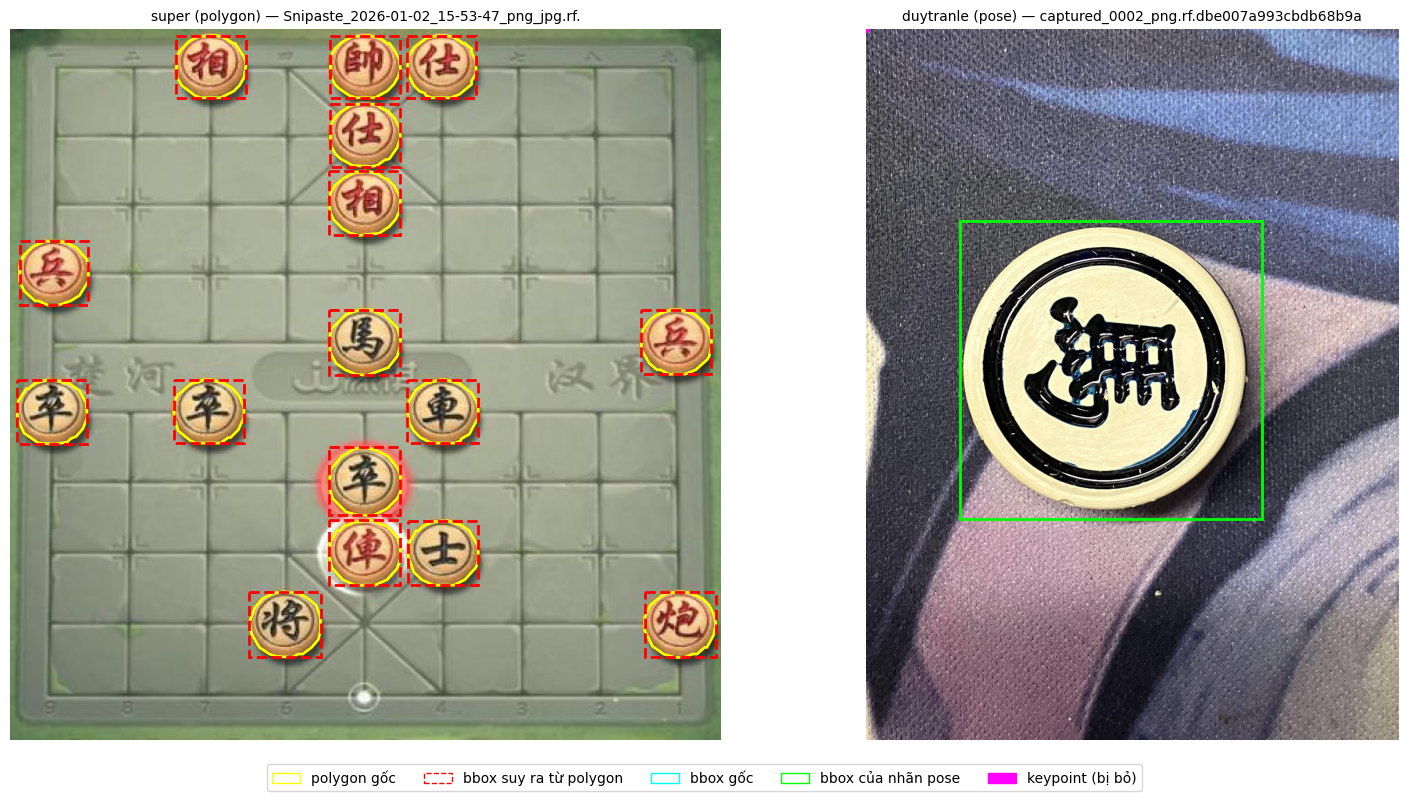

In [14]:
import matplotlib.patches as mpatches
from PIL import Image

def find_example(dataset, want):
    # Tìm ảnh đầu tiên của bộ `dataset` có ít nhất một dòng nhãn thoả điều kiện want(parts, names)
    yf = glob.glob(f'{paths[dataset]}/**/data.yaml', recursive=True)[0]
    root, names = os.path.dirname(yf), load_names(yf)
    for lf in sorted(glob.glob(f'{root}/*/labels/*.txt')):
        rows = [l.split() for l in open(lf) if l.strip()]
        if any(want(r, names) for r in rows):
            stem = os.path.splitext(os.path.basename(lf))[0]
            img_dir = os.path.join(os.path.dirname(os.path.dirname(lf)), 'images')
            for ext in IMG_EXT:
                if os.path.exists(f'{img_dir}/{stem}{ext}'):
                    return f'{img_dir}/{stem}{ext}', rows, names
    return None, None, None

is_piece_polygon = lambda r, n: len(r) > 5 and n[int(r[0])].lower() != 'board'
is_pose = lambda r, n: len(r) > 5

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, (ds, want, mode) in zip(axes, [('super', is_piece_polygon, 'polygon'), ('duytranle', is_pose, 'pose')]):
    img_path, rows, names = find_example(ds, want)
    if img_path is None:
        ax.set_title(f'{ds}: không tìm thấy ví dụ'); ax.axis('off'); continue
    im = Image.open(img_path).convert('RGB'); W, H = im.size
    ax.imshow(im)
    for r in rows:
        cname = names[int(r[0])]
        vals = list(map(float, r[1:]))
        if mode == 'polygon' and len(vals) > 4 and cname.lower() != 'board':
            xs, ys = vals[0::2], vals[1::2]
            ax.add_patch(mpatches.Polygon(list(zip([x * W for x in xs], [y * H for y in ys])),
                                          closed=True, fill=False, ec='yellow', lw=2))
            x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)       # bbox bao ngoài polygon
            ax.add_patch(mpatches.Rectangle((x0 * W, y0 * H), (x1 - x0) * W, (y1 - y0) * H,
                                            fill=False, ec='red', lw=2, ls='--'))
        elif mode == 'pose' and len(vals) > 4:
            x, y, w, h = vals[:4]                                        # 4 giá trị đầu = bbox
            ax.add_patch(mpatches.Rectangle(((x - w / 2) * W, (y - h / 2) * H), w * W, h * H,
                                            fill=False, ec='lime', lw=2))
            kp = vals[4:]
            step = 3 if len(kp) % 3 == 0 else 2                          # (x, y, visible) hoặc (x, y)
            ax.scatter([k * W for k in kp[0::step]], [k * H for k in kp[1::step]], s=12, c='magenta')
        elif len(vals) == 4:
            x, y, w, h = vals
            ax.add_patch(mpatches.Rectangle(((x - w / 2) * W, (y - h / 2) * H), w * W, h * H,
                                            fill=False, ec='cyan', lw=1))
    ax.set_title(f'{ds} ({mode}) — {os.path.basename(img_path)[:40]}', fontsize=10); ax.axis('off')

handles = [mpatches.Patch(ec='yellow', fill=False, label='polygon gốc'),
           mpatches.Patch(ec='red', fill=False, ls='--', label='bbox suy ra từ polygon'),
           mpatches.Patch(ec='cyan', fill=False, label='bbox gốc'),
           mpatches.Patch(ec='lime', fill=False, label='bbox của nhãn pose'),
           mpatches.Patch(color='magenta', label='keypoint (bị bỏ)')]
fig.legend(handles=handles, loc='lower center', ncol=5, fontsize=10)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

---
# 4. Làm sạch và chuẩn hoá về 14 lớp

## Làm sạch và ánh xạ về 14 lớp chuẩn
Duyệt từng bộ: đổi tên lớp về 14 lớp chuẩn, bỏ dòng `board`, bỏ ảnh có lớp `None`, chuyển polygon (super) và pose (duytranle) về bbox, kẹp box vào khung ảnh. Ảnh và nhãn sạch được gom vào /content/pool kèm manifest.csv (bộ, tập gốc, mã ảnh gốc). In bảng số box theo lớp và thống kê các thao tác đã làm.

**Các quy tắc chính trong ô dưới** (⚠ là phần quan trọng nhất của notebook):

| Quy tắc | Ví dụ | Lý do |
|---|---|---|
| Đổi tên lớp: viết thường, `-`/khoảng trắng → `_` | `Black-Guard` → `black_guard` | Các bộ viết tên khác nhau |
| Ánh xạ tên quân đồng nghĩa (`PIECE_ALIAS`) | `guard`→`advisor`, `elephant`→`bishop`, `chariot`→`rook`, `horse`→`knight`, `general`→`king`, `soldier`→`pawn` | Đưa về cùng 1 bộ tên |
| Bỏ dòng `board` nhưng giữ ảnh | | Chỉ cần nhận diện quân |
| Bỏ **cả ảnh** có lớp `None` | | Ảnh có vật không xác định, giữ lại sẽ thành nhãn thiếu |
| Kẹp bbox vào khung ảnh, bỏ box < 0.5% | | Tránh box lỗi làm hỏng loss |
| Gặp tên lớp lạ → **dừng và báo lỗi** | | Không để lớp sai lọt vào dataset một cách âm thầm |

Mỗi ảnh được đổi tên thành `<bộ>__<tên gốc>` để không trùng tên giữa các bộ và vẫn truy được nguồn gốc.

In [15]:
import shutil, glob, os, yaml
import pandas as pd
from collections import Counter

SPLITS = ['train', 'valid', 'test']
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
POOL = '/content/pool'          # nơi gom toàn bộ ảnh + nhãn đã làm sạch

# ⚠ 14 lớp chuẩn — THỨ TỰ NÀY QUYẾT ĐỊNH CLASS ID (0..13), phía robot phải dùng đúng thứ tự này
CLASSES = [f'{c}_{p}' for c in ['black', 'red']
           for p in ['advisor', 'bishop', 'cannon', 'king', 'knight', 'pawn', 'rook']]
CLASS_ID = {c: i for i, c in enumerate(CLASSES)}
# Tên đồng nghĩa giữa các bộ -> tên chuẩn
PIECE_ALIAS = {'elephant': 'bishop', 'chariot': 'rook', 'general': 'king',
               'horse': 'knight', 'guard': 'advisor', 'soldier': 'pawn'}
DROP_LINES = {'board'}      # bỏ dòng nhãn, giữ ảnh
DROP_IMAGES = {'none'}      # bỏ cả ảnh có lớp này
POSE_DATASETS = {'duytranle'}   # nhãn dạng: lớp x y w h + keypoint

def load_names(yaml_path):
    with open(yaml_path, encoding='utf-8') as f:
        names = yaml.safe_load(f)['names']
    if isinstance(names, dict):
        names = [names[k] for k in sorted(names)]
    return names

def source_id(filename):
    return filename.split('.rf.')[0]

def canon(raw):
    # Chuẩn hoá tên lớp gốc -> 1 trong 14 lớp chuẩn (hoặc tín hiệu bỏ dòng / bỏ ảnh)
    n = raw.strip().lower().replace('-', '_').replace(' ', '_')
    if n in DROP_LINES:
        return 'DROP_LINE'
    if n in DROP_IMAGES:
        return 'DROP_IMAGE'
    color, piece = n.split('_', 1)
    name = f'{color}_{PIECE_ALIAS.get(piece, piece)}'
    if name not in CLASS_ID:
        raise ValueError(f'Lớp lạ chưa ánh xạ: {raw}')   # dừng ngay, không để lớp sai lọt qua
    return name

if os.path.exists(POOL):
    shutil.rmtree(POOL)
os.makedirs(f'{POOL}/images'); os.makedirs(f'{POOL}/labels')

rows, cls_count, stats = [], {}, {}
for name, p in paths.items():
    yf = glob.glob(f'{p}/**/data.yaml', recursive=True)[0]
    root = os.path.dirname(yf)
    names = load_names(yf)
    pose = name in POSE_DATASETS
    st, cnt = Counter(), Counter()

    for split in SPLITS:
        img_dir, lbl_dir = f'{root}/{split}/images', f'{root}/{split}/labels'
        if not os.path.isdir(lbl_dir):
            continue
        imgs = {os.path.splitext(f)[0]: f for f in os.listdir(img_dir) if f.lower().endswith(IMG_EXT)}
        for lf in os.listdir(lbl_dir):
            stem = os.path.splitext(lf)[0]
            if stem not in imgs:
                continue
            out, kept, skip = [], [], False
            for line in open(f'{lbl_dir}/{lf}'):
                parts = line.split()
                if not parts:
                    continue
                c = canon(names[int(parts[0])])
                if c == 'DROP_LINE':
                    st['dòng board bỏ'] += 1
                    continue
                if c == 'DROP_IMAGE':
                    skip = True
                    break
                vals = list(map(float, parts[1:]))
                if len(vals) == 4:                                  # bbox chuẩn
                    x, y, w, h = vals
                elif pose and len(vals) >= 4:                       # pose: 4 số đầu là bbox
                    x, y, w, h = vals[:4]; st['pose→bbox'] += 1
                elif len(vals) >= 6 and len(vals) % 2 == 0:         # polygon: lấy hình chữ nhật bao ngoài
                    xs, ys = vals[0::2], vals[1::2]
                    x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
                    x, y, w, h = (x0 + x1) / 2, (y0 + y1) / 2, x1 - x0, y1 - y0
                    st['polygon→bbox'] += 1
                else:
                    st['dòng lỗi bỏ'] += 1
                    continue
                # Kẹp box vào khung ảnh [0, 1] rồi bỏ box quá nhỏ (< 0.5% cạnh ảnh)
                x0, y0 = max(0.0, x - w / 2), max(0.0, y - h / 2)
                x1, y1 = min(1.0, x + w / 2), min(1.0, y + h / 2)
                w, h = x1 - x0, y1 - y0
                if w <= 0.005 or h <= 0.005:
                    st['box quá nhỏ/lỗi bỏ'] += 1
                    continue
                out.append(f'{CLASS_ID[c]} {(x0 + x1) / 2:.6f} {(y0 + y1) / 2:.6f} {w:.6f} {h:.6f}')
                kept.append(c)
            if skip:
                st['ảnh bỏ (lớp None)'] += 1
                continue
            if not out:
                st['ảnh bỏ (không còn box)'] += 1          # vd: ảnh chỉ có bàn cờ
                continue
            new = f'{name}__{imgs[stem]}'                  # tiền tố tên bộ để không trùng tên
            shutil.copy(f'{img_dir}/{imgs[stem]}', f'{POOL}/images/{new}')
            with open(f'{POOL}/labels/{os.path.splitext(new)[0]}.txt', 'w') as f:
                f.write('\n'.join(out) + '\n')
            cnt.update(kept)
            # manifest: mỗi ảnh 1 dòng — nguồn, tập gốc, mã ảnh gốc (để gom nhóm ở bước sau)
            rows.append({'file': new, 'dataset': name, 'orig_split': split,
                         'source_id': f'{name}__{source_id(imgs[stem])}', 'n_box': len(out)})
    cls_count[name], stats[name] = cnt, st

manifest = pd.DataFrame(rows)
manifest.to_csv(f'{POOL}/manifest.csv', index=False)

print('Số ảnh sạch theo bộ và tập gốc:')
print(manifest.groupby(['dataset', 'orig_split']).size().unstack(fill_value=0))
table = pd.DataFrame({n: [c.get(k, 0) for k in CLASSES] for n, c in cls_count.items()}, index=CLASSES)
table['tong'] = table.sum(axis=1)
print('\nSố box theo lớp chuẩn:')
print(table)
print('\nThao tác đã thực hiện:')
for n, s in stats.items():
    print(f'  {n}: {dict(s)}')

Số ảnh sạch theo bộ và tập gốc:
orig_split         test  train  valid
dataset                              
duytranle           151   1202    150
new_chinese_chess   139    864    250
scara                72   1518    144
super                57   2004    257

Số box theo lớp chuẩn:
               super  scara  new_chinese_chess  duytranle   tong
black_advisor   2870   3084                 89       2462   8505
black_bishop    2465   2742                 90       2332   7629
black_cannon    1341   3253                 89       1903   6586
black_king      1629   1396                 90       1291   4406
black_knight    1921   2464                 92       1779   6256
black_pawn      5217   5949                 89       4265  15520
black_rook      2684   2951                 90       1866   7591
red_advisor     2752   3231                105       2385   8473
red_bishop      2616   2763                104       2333   7816
red_cannon      1512   2672                104       1792   6080
r

> **Kết quả:** còn **6 808 ảnh sạch**. `super` bỏ 2 137 ảnh chỉ có bàn cờ (không còn quân nào), `new_chinese_chess` bỏ 88 ảnh có lớp `None`, `duytranle` chuyển 31 520 nhãn pose → bbox.

### 📊 Biểu đồ: phân bố box theo lớp và theo nguồn
- **Biểu đồ trái:** mỗi lớp được đóng góp bởi nhiều bộ → không lớp nào phụ thuộc một nguồn duy nhất.
- **Mất cân bằng lớp là tự nhiên:** mỗi bên có 5 Tốt nhưng chỉ 1 Tướng, nên `pawn` nhiều gấp ~3.5 lần `king`. Mức chênh này vừa phải (lớp ít nhất vẫn > 4 000 box), **không cần** cân bằng lại bằng trọng số hay oversampling.
- **Biểu đồ phải:** số box mỗi ảnh — ảnh bàn cờ đầy đủ có tới 32 quân, ảnh quân rời chỉ có vài quân → dữ liệu có cả hai bối cảnh.

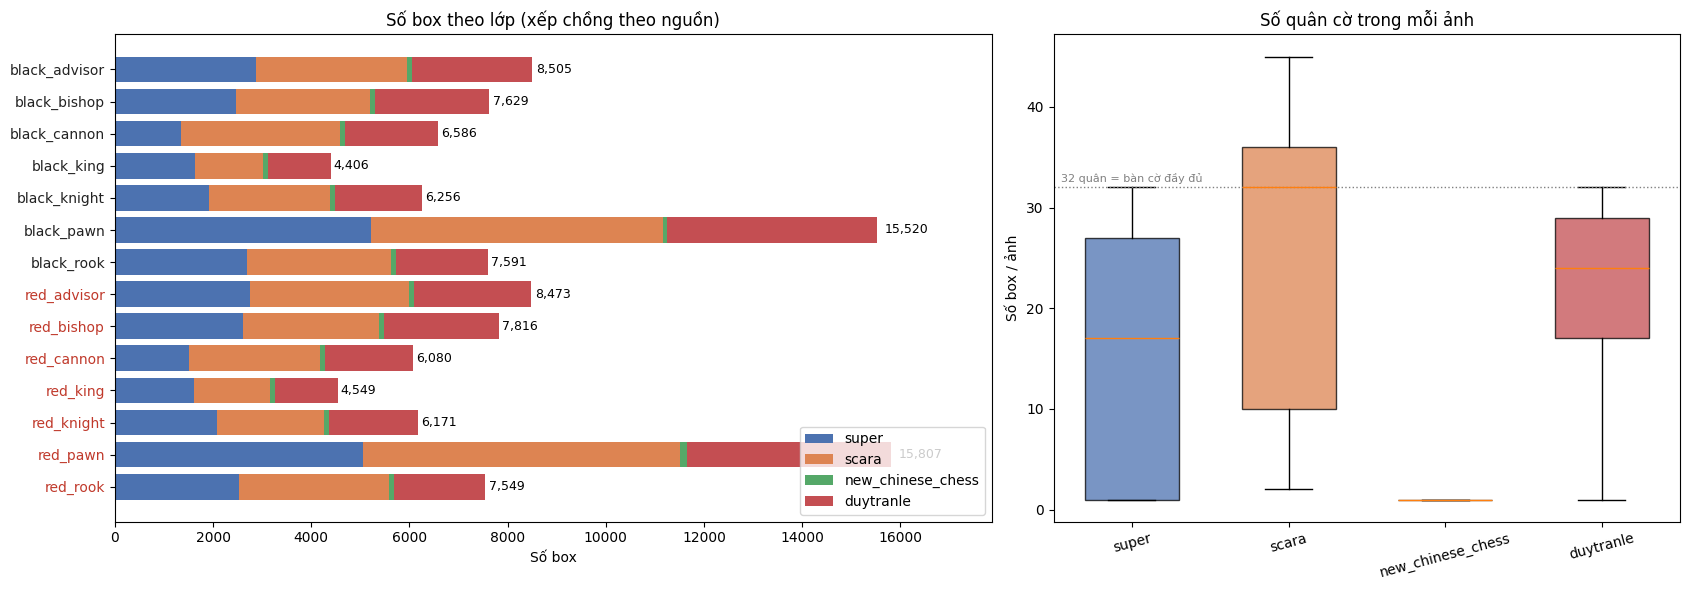

Tổng ảnh: 6,808 | tổng box: 112,938 | lớp nhiều nhất / ít nhất = red_pawn / black_king = 3.6 lần


In [16]:
import numpy as np
import matplotlib.pyplot as plt

DS_COLORS = {'super': '#4C72B0', 'scara': '#DD8452', 'new_chinese_chess': '#55A868', 'duytranle': '#C44E52'}
ds_order = [d for d in DS_COLORS if d in table.columns]

fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={'width_ratios': [1.4, 1]})

# (a) Số box theo lớp, xếp chồng theo nguồn
ax = axes[0]
left = np.zeros(len(CLASSES))
for d in ds_order:
    ax.barh(CLASSES, table[d].values, left=left, color=DS_COLORS[d], label=d)
    left += table[d].values
for i, v in enumerate(table['tong'].values):
    ax.text(v * 1.01, i, f'{v:,}', va='center', fontsize=9)
ax.invert_yaxis(); ax.set_xlabel('Số box'); ax.set_xlim(0, table['tong'].max() * 1.13)
ax.set_title('Số box theo lớp (xếp chồng theo nguồn)'); ax.legend(loc='lower right')
for lbl in ax.get_yticklabels():
    lbl.set_color('#C0392B' if lbl.get_text().startswith('red') else '#222')

# (b) Phân bố số box trong một ảnh, theo từng bộ
ax = axes[1]
data = [manifest.loc[manifest.dataset == d, 'n_box'].values for d in ds_order]
bp = ax.boxplot(data, vert=True, patch_artist=True, widths=0.6, showfliers=False)
for patch, d in zip(bp['boxes'], ds_order):
    patch.set_facecolor(DS_COLORS[d]); patch.set_alpha(0.75)
ax.set_xticks(range(1, len(ds_order) + 1)); ax.set_xticklabels(ds_order, rotation=15)
ax.axhline(32, color='gray', ls=':', lw=1); ax.text(0.55, 32.5, '32 quân = bàn cờ đầy đủ', fontsize=8, color='gray')
ax.set_ylabel('Số box / ảnh'); ax.set_title('Số quân cờ trong mỗi ảnh')
plt.tight_layout(); plt.show()

ratio = table['tong'].max() / table['tong'].min()
print(f'Tổng ảnh: {len(manifest):,} | tổng box: {table["tong"].sum():,} | '
      f'lớp nhiều nhất / ít nhất = {table["tong"].idxmax()} / {table["tong"].idxmin()} = {ratio:.1f} lần')

---
# 5. Gom nhóm ảnh trùng — chống rò rỉ dữ liệu (data leakage)

## Gom nhóm ảnh trùng (cùng ảnh gốc hoặc gần giống nhau)
Tính perceptual hash cho từng ảnh trong /content/pool rồi gom nhóm bằng union-find: ảnh cùng source_id là một nhóm; ảnh cùng bộ chỉ nối khi hash trùng khít (SAME_DS_T); ảnh khác bộ nối khi khoảng cách hash <= CROSS_DS_T. In kích thước nhóm, thành phần của nhóm lớn nhất, số nhóm nối nhiều bộ, và vẽ vài cặp ảnh trùng khác bộ để kiểm tra bằng mắt. Chưa xóa gì.

**Vì sao bước này quan trọng?**
Roboflow tạo 2–3 bản augment (xoay nhẹ, đổi sáng, ...) từ **cùng một ảnh gốc**. Nếu một bản nằm trong train và bản kia nằm trong test, mô hình đã "nhìn thấy" ảnh test khi học → điểm test **cao giả tạo**, không phản ánh khả năng thật.

**Cách làm:**
1. **Perceptual hash (pHash):** biến mỗi ảnh thành chuỗi 64 bit dựa trên các thành phần tần số thấp (DCT). Hai ảnh gần giống nhau → hash khác nhau rất ít bit (khoảng cách Hamming nhỏ), dù khác kích thước hay độ sáng.
2. **Union-Find (Disjoint Set):** cấu trúc dữ liệu gộp các ảnh "dính" nhau thành nhóm, có tính bắc cầu (A≈B, B≈C ⇒ A, B, C cùng nhóm).
3. Quy tắc nối:
   - cùng `source_id` (cùng ảnh gốc Roboflow) → luôn nối
   - **cùng bộ**: chỉ nối khi hash trùng khít (`SAME_DS_T = 0`) — vì ảnh bàn cờ trong cùng bộ rất giống nhau, ngưỡng lỏng sẽ gộp cả nghìn ảnh thành một nhóm khổng lồ
   - **khác bộ**: nối khi khoảng cách ≤ 4 bit (`CROSS_DS_T = 4`) — để phát hiện ảnh bị đăng lại ở bộ khác

In [17]:
import numpy as np, imagehash, matplotlib.pyplot as plt
from PIL import Image
from collections import defaultdict

SAME_DS_T = 0    # ngưỡng phash nối ảnh CÙNG bộ (0 = hash trùng khít; đặt -1 để chỉ gom theo source_id)
CROSS_DS_T = 4   # ngưỡng phash nối ảnh KHÁC bộ
manifest = pd.read_csv(f'{POOL}/manifest.csv')
n = len(manifest)

# 1) perceptual hash: mỗi ảnh -> số nguyên 64 bit
hashes = []
for f in manifest['file']:
    try:
        with Image.open(f'{POOL}/images/{f}') as im:
            hashes.append(int(str(imagehash.phash(im)), 16))
    except Exception as e:
        print('Lỗi ảnh:', f, e); hashes.append(0)
H = np.array(hashes, dtype=np.uint64)
ds = manifest['dataset'].values

# 2) union-find: mỗi ảnh ban đầu là một nhóm riêng
parent = list(range(n))
def find(a):
    # tìm gốc của nhóm (kèm nén đường đi cho nhanh)
    while parent[a] != a:
        parent[a] = parent[parent[a]]
        a = parent[a]
    return a
def union(a, b):
    # gộp hai nhóm
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

# 2a) cùng ảnh gốc Roboflow -> cùng nhóm
first = {}
for i, s in enumerate(manifest['source_id']):
    if s in first: union(first[s], i)
    else: first[s] = i

def popcount64(x):
    # đếm số bit 1 -> khoảng cách Hamming khi áp dụng lên XOR của hai hash
    return np.unpackbits(x.view(np.uint8).reshape(-1, 8), axis=1).sum(axis=1)

# 2b) so sánh hash từng cặp (vector hoá theo hàng), nối khi khoảng cách <= ngưỡng
for i in range(n - 1):
    d = popcount64(H[i + 1:] ^ H[i])
    thr = np.where(ds[i + 1:] == ds[i], SAME_DS_T, CROSS_DS_T)
    for j in (np.nonzero(d <= thr)[0] + i + 1):
        union(i, int(j))

manifest['group'] = [find(i) for i in range(n)]

# 3) thống kê
g = manifest.groupby('group')
sizes = g.size().sort_values(ascending=False)
multi_ds = g['dataset'].nunique()
multi_sp = g['orig_split'].nunique()
print(f'Ảnh: {n} | nhóm: {len(sizes)} | nhóm lớn nhất: {sizes.head(5).tolist()}')
top = sizes.index[0]
print('Thành phần nhóm lớn nhất:', manifest[manifest.group == top].groupby(['dataset', 'orig_split']).size().to_dict())
print(f'Nhóm trải qua >1 bộ: {(multi_ds > 1).sum()} | nhóm nằm ở >1 tập gốc: {(multi_sp > 1).sum()}')
if sizes.iloc[0] > 0.03 * n:
    print('⚠ Nhóm lớn nhất quá lớn: đặt SAME_DS_T = -1 và chạy lại.')

print('\nCặp bộ có ảnh trùng nhau:')
pair = defaultdict(int)
for gid in multi_ds[multi_ds > 1].index:
    sets = tuple(sorted(manifest.loc[manifest.group == gid, 'dataset'].unique()))
    pair[sets] += 1
for k, v in sorted(pair.items(), key=lambda kv: -kv[1]):
    print(' ', k, v)

# 4) vẽ vài cặp trùng khác bộ để kiểm tra bằng mắt
cross = multi_ds[multi_ds > 1].index[:3]
if len(cross):
    fig, axes = plt.subplots(len(cross), 2, figsize=(8, 3.5 * len(cross)), squeeze=False)
    for r, gid in enumerate(cross):
        sub = manifest[manifest.group == gid].drop_duplicates('dataset').head(2)
        for c, (_, row) in enumerate(sub.iterrows()):
            axes[r][c].imshow(Image.open(f'{POOL}/images/{row.file}'))
            axes[r][c].set_title(row.dataset); axes[r][c].axis('off')
    plt.tight_layout(); plt.show()

Ảnh: 6808 | nhóm: 4265 | nhóm lớn nhất: [48, 44, 26, 26, 24]
Thành phần nhóm lớn nhất: {('scara', 'train'): 45, ('scara', 'valid'): 3}
Nhóm trải qua >1 bộ: 0 | nhóm nằm ở >1 tập gốc: 191

Cặp bộ có ảnh trùng nhau:


> **Đọc kết quả:**
> - 6 808 ảnh → **4 265 nhóm**: trung bình 1.6 ảnh/nhóm, đúng với việc Roboflow nhân bản ảnh gốc.
> - Không có ảnh trùng giữa các bộ khác nhau (0 nhóm trải qua >1 bộ).
> - ⚠ **191 nhóm nằm ở hơn một tập gốc** → cách chia train/valid/test **gốc** của các tác giả **đã bị rò rỉ** (bản augment của cùng một ảnh nằm ở cả train lẫn valid/test). Đây là lý do **không dùng lại cách chia gốc** mà chia lại theo nhóm.

### 📊 Biểu đồ: kích thước nhóm + ví dụ một nhóm ảnh trùng

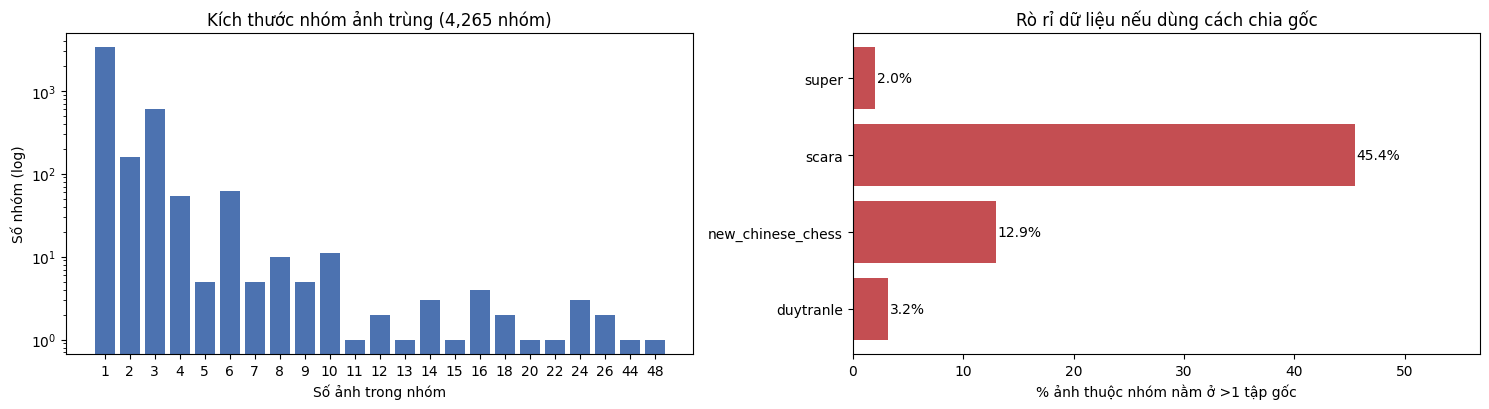

191 nhóm / 1044 ảnh bị rò rỉ giữa các tập gốc


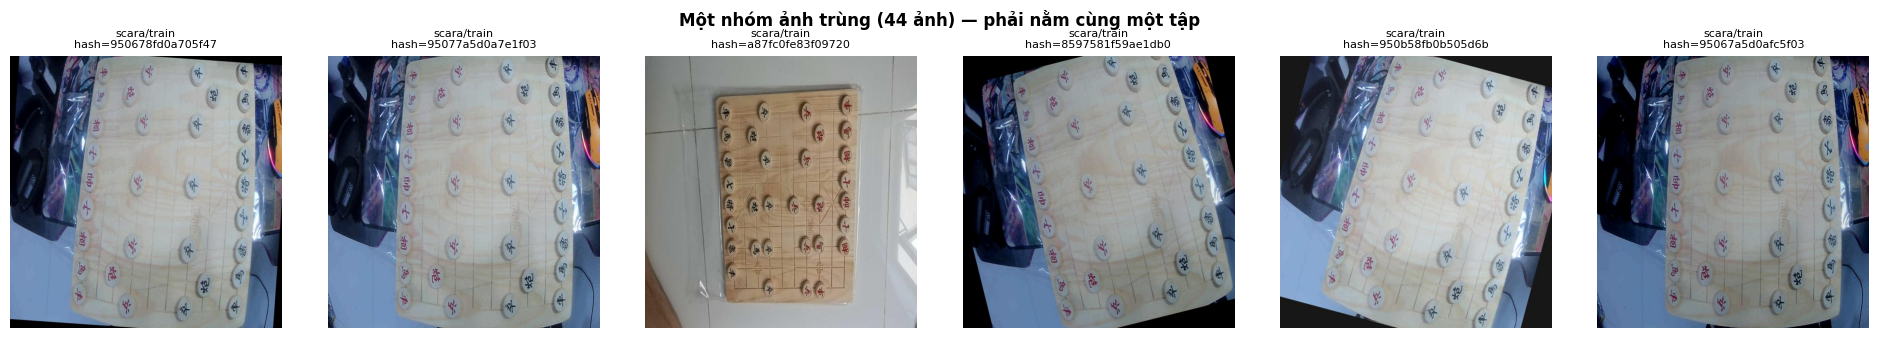

In [18]:
# (a) Phân bố kích thước nhóm  (b) mức độ rò rỉ ở cách chia gốc
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
vc = sizes.value_counts().sort_index()
axes[0].bar(vc.index.astype(str), vc.values, color='#4C72B0')
axes[0].set_yscale('log'); axes[0].set_xlabel('Số ảnh trong nhóm'); axes[0].set_ylabel('Số nhóm (log)')
axes[0].set_title(f'Kích thước nhóm ảnh trùng ({len(sizes):,} nhóm)')
if len(vc) > 20:
    axes[0].set_xticks(axes[0].get_xticks()[::max(1, len(vc) // 15)])

leak_groups = multi_sp[multi_sp > 1].index
leak_imgs = manifest.group.isin(leak_groups)
leak = manifest.assign(leak=leak_imgs).groupby('dataset')['leak'].mean() * 100
axes[1].barh(leak.index, leak.values, color='#C44E52')
for i, v in enumerate(leak.values):
    axes[1].text(v + 0.2, i, f'{v:.1f}%', va='center')
axes[1].set_xlabel('% ảnh thuộc nhóm nằm ở >1 tập gốc')
axes[1].set_title('Rò rỉ dữ liệu nếu dùng cách chia gốc')
axes[1].set_xlim(0, max(leak.max() * 1.25, 1))
plt.tight_layout(); plt.show()
print(f'{len(leak_groups)} nhóm / {leak_imgs.sum()} ảnh bị rò rỉ giữa các tập gốc')

# (c) Xem các ảnh trong một nhóm lớn: chúng là các bản augment của cùng một cảnh
gid = sizes.index[min(1, len(sizes) - 1)]
members = manifest[manifest.group == gid].head(6)
fig, axes = plt.subplots(1, len(members), figsize=(3.2 * len(members), 3.4), squeeze=False)
for ax, (_, r) in zip(axes[0], members.iterrows()):
    ax.imshow(Image.open(f'{POOL}/images/{r.file}')); ax.axis('off')
    ax.set_title(f'{r.dataset}/{r.orig_split}\nhash={H[r.name]:016x}'[:60], fontsize=8)
fig.suptitle(f'Một nhóm ảnh trùng ({sizes[gid]} ảnh) — phải nằm cùng một tập', fontweight='bold')
plt.tight_layout(); plt.show()

---
# 6. Chia train / val / test và xuất dataset

## Chia train/val/test theo nhóm và xuất dataset hợp nhất
Chia ~80/10/10 theo ảnh, giữ nguyên mỗi nhóm trong cùng một tập và giữ tỷ lệ các bộ trong từng tập (StratifiedGroupKFold). Kiểm tra tỷ lệ val/test của từng bộ trước; nếu lệch thì dừng, không ghi file. Nếu ổn thì copy ảnh/nhãn vào /content/merged, ghi data.yaml với 14 lớp chuẩn, in số box theo lớp ở mỗi tập, rồi nén lưu bản sao lên Drive (ghi đè merged_v1.zip cũ).

**StratifiedGroupKFold** (scikit-learn) thoả mãn đồng thời hai điều kiện:
- **Group:** mọi ảnh cùng một nhóm vào cùng một fold → không rò rỉ.
- **Stratified** theo `dataset`: mỗi fold có tỷ lệ 4 bộ giống nhau → tập test đại diện cho mọi nguồn.

Chia thành 10 fold: fold 0 → **test** (10%), fold 1 → **val** (10%), 8 fold còn lại → **train** (80%). `random_state=42` để kết quả chia **tái lập được**.

| Tập | Vai trò |
|---|---|
| train | Mô hình học trọng số |
| val | Theo dõi sau mỗi epoch, chọn `best.pt`, early stopping |
| test | **Chỉ dùng một lần** ở cuối để báo cáo kết quả khách quan |

In [19]:
from sklearn.model_selection import StratifiedGroupKFold
import yaml

MERGED = '/content/merged'
# 10 fold, giữ nhóm nguyên vẹn, cân bằng tỷ lệ theo bộ nguồn; random_state cố định để tái lập
sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
fold = np.zeros(len(manifest), dtype=int)
for k, (_, te) in enumerate(sgkf.split(manifest, manifest['dataset'], manifest['group'])):
    fold[te] = k
manifest['split'] = np.where(fold == 0, 'test', np.where(fold == 1, 'val', 'train'))

# ⚠ kiểm tra tỷ lệ trước khi ghi file: mỗi bộ phải có val/test trong khoảng 5–20%
share = manifest.groupby(['dataset', 'split']).size().unstack(fill_value=0)
for c in ['train', 'val', 'test']:
    if c not in share: share[c] = 0
pct = share[['val', 'test']].div(share[['train', 'val', 'test']].sum(axis=1), axis=0) * 100
print('Số ảnh theo bộ và tập:'); print(share[['train', 'val', 'test']])
print('\nTỷ lệ val/test mỗi bộ (%):'); print(pct.round(1))
bad = pct[(share[['train', 'val', 'test']].sum(axis=1) >= 100) & ((pct < 5).any(axis=1) | (pct > 20).any(axis=1))]
if len(bad):
    raise ValueError(f'Chia tập lệch ở bộ: {list(bad.index)}. Xem lại bước gom nhóm (nhóm quá lớn?), chưa ghi file.')

# Ghi dataset theo cấu trúc chuẩn YOLO: <split>/images và <split>/labels
if os.path.exists(MERGED):
    shutil.rmtree(MERGED)
for s in ['train', 'val', 'test']:
    os.makedirs(f'{MERGED}/{s}/images'); os.makedirs(f'{MERGED}/{s}/labels')

for _, r in manifest.iterrows():
    stem = os.path.splitext(r.file)[0]
    shutil.copy(f'{POOL}/images/{r.file}', f'{MERGED}/{r.split}/images/{r.file}')
    shutil.copy(f'{POOL}/labels/{stem}.txt', f'{MERGED}/{r.split}/labels/{stem}.txt')

# data.yaml: file cấu hình Ultralytics đọc khi train (đường dẫn + 14 tên lớp theo đúng thứ tự id)
with open(f'{MERGED}/data.yaml', 'w') as f:
    yaml.safe_dump({'path': MERGED, 'train': 'train/images', 'val': 'val/images',
                    'test': 'test/images', 'nc': len(CLASSES), 'names': CLASSES},
                   f, allow_unicode=True, sort_keys=False)
manifest.to_csv(f'{MERGED}/manifest.csv', index=False)

box = {s: Counter() for s in ['train', 'val', 'test']}
for s in box:
    for lf in glob.glob(f'{MERGED}/{s}/labels/*.txt'):
        for line in open(lf):
            if line.strip():
                box[s][CLASSES[int(line.split()[0])]] += 1
print('\nSố box theo lớp và tập:')
print(pd.DataFrame(box, index=CLASSES))

# Nén và lưu lên Drive -> notebook train chỉ cần giải nén file này
shutil.make_archive(f'{BASE}/merged/merged_v1', 'zip', MERGED)
print('\nĐã lưu', f'{BASE}/merged/merged_v1.zip')

Số ảnh theo bộ và tập:
split              train  val  test
dataset                            
duytranle           1184  155   164
new_chinese_chess   1000  128   125
scara               1335  216   183
super               1837  240   241

Tỷ lệ val/test mỗi bộ (%):
split               val  test
dataset                      
duytranle          10.3  10.9
new_chinese_chess  10.2  10.0
scara              12.5  10.6
super              10.4  10.4

Số box theo lớp và tập:
               train   val  test
black_advisor   6646   974   885
black_bishop    5977   825   827
black_cannon    5200   752   634
black_king      3440   510   456
black_knight    4888   672   696
black_pawn     12194  1694  1632
black_rook      5888   863   840
red_advisor     6625   963   885
red_bishop      6113   851   852
red_cannon      4888   598   594
red_king        3539   528   482
red_knight      4847   657   667
red_pawn       12395  1725  1687
red_rook        5856   858   835

Đã lưu /content/drive/MyDrive/da

### ✅ Kiểm chứng cách chia + 📊 biểu đồ phân bố
Ô dưới **kiểm tra tự động** rằng không có nhóm nào bị tách sang hai tập (nếu có sẽ báo lỗi), rồi vẽ:
- (a) số ảnh mỗi tập theo nguồn;
- (b) tỷ lệ % box theo lớp ở từng tập — ba đường gần như trùng nhau nghĩa là **val và test có cùng phân bố lớp với train**, nên điểm đánh giá đáng tin.

✅ 4,265 nhóm, không nhóm nào bị tách giữa train/val/test


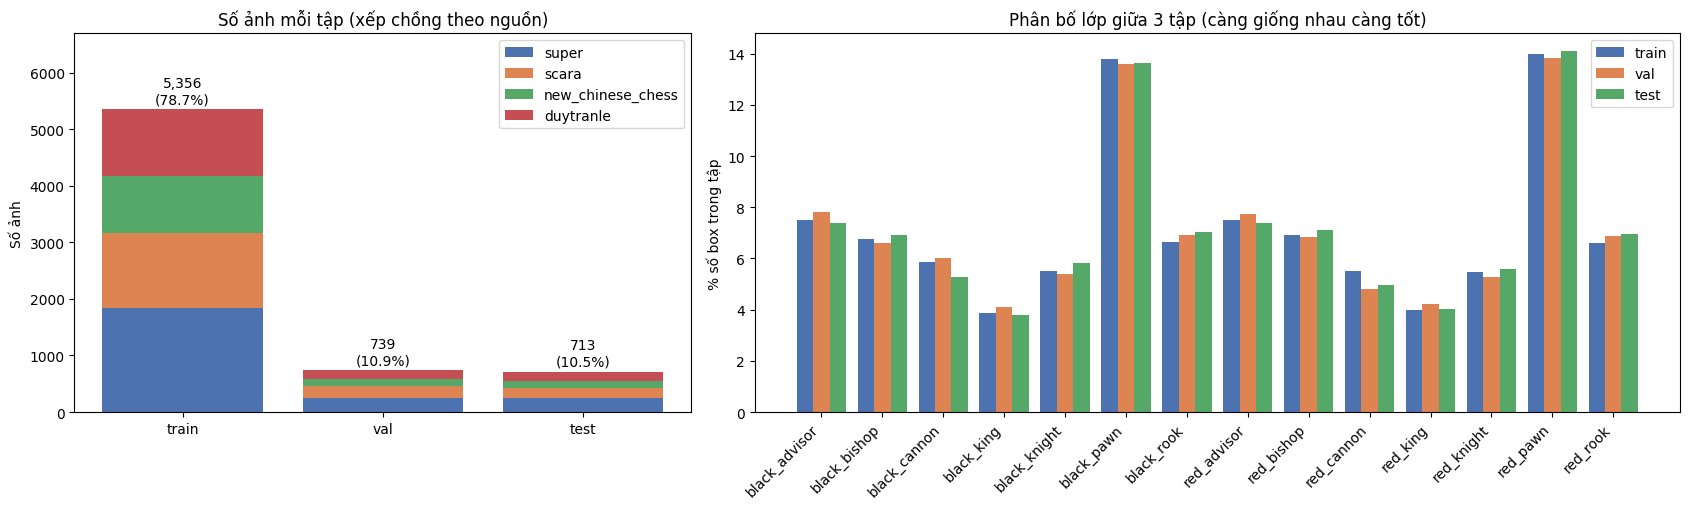

Chênh lệch tỷ lệ lớn nhất giữa train và test: 0.58 điểm %


In [20]:
# ⚠ Kiểm tra rò rỉ sau khi chia: mỗi nhóm chỉ được nằm trong đúng 1 tập
n_split_per_group = manifest.groupby('group')['split'].nunique()
assert (n_split_per_group == 1).all(), 'Có nhóm bị tách sang nhiều tập!'
print(f'✅ {len(n_split_per_group):,} nhóm, không nhóm nào bị tách giữa train/val/test')

SPLIT_ORDER = ['train', 'val', 'test']
SPLIT_COLORS = {'train': '#4C72B0', 'val': '#DD8452', 'test': '#55A868'}
fig, axes = plt.subplots(1, 2, figsize=(17, 5.2), gridspec_kw={'width_ratios': [1, 1.5]})

# (a) Số ảnh theo tập, xếp chồng theo nguồn
sh = share[SPLIT_ORDER].T
bottom = np.zeros(len(SPLIT_ORDER))
for d in [d for d in DS_COLORS if d in sh.columns]:
    axes[0].bar(SPLIT_ORDER, sh[d].values, bottom=bottom, color=DS_COLORS[d], label=d)
    bottom += sh[d].values
for i, v in enumerate(bottom):
    axes[0].text(i, v + bottom.max() * 0.02, f'{int(v):,}\n({v / bottom.sum() * 100:.1f}%)', ha='center', fontsize=10)
axes[0].set_ylim(0, bottom.max() * 1.25); axes[0].set_ylabel('Số ảnh')
axes[0].set_title('Số ảnh mỗi tập (xếp chồng theo nguồn)'); axes[0].legend()

# (b) Tỷ lệ box theo lớp ở từng tập
box_df = pd.DataFrame(box, index=CLASSES)[SPLIT_ORDER]
pct_cls = box_df / box_df.sum() * 100
x = np.arange(len(CLASSES)); wbar = 0.27
for k, s in enumerate(SPLIT_ORDER):
    axes[1].bar(x + (k - 1) * wbar, pct_cls[s].values, wbar, color=SPLIT_COLORS[s], label=s)
axes[1].set_xticks(x); axes[1].set_xticklabels(CLASSES, rotation=45, ha='right')
axes[1].set_ylabel('% số box trong tập'); axes[1].set_title('Phân bố lớp giữa 3 tập (càng giống nhau càng tốt)')
axes[1].legend()
plt.tight_layout(); plt.show()

print('Chênh lệch tỷ lệ lớn nhất giữa train và test: '
      f'{(pct_cls["train"] - pct_cls["test"]).abs().max():.2f} điểm %')

---
# 7. Kiểm tra nhãn bằng mắt

## Kiểm tra nhãn bằng mắt
Vẽ box và tên lớp lên 2 ảnh ngẫu nhiên của mỗi bộ trong tập train của /content/merged, để chắc việc chuyển đổi nhãn (polygon/pose → bbox) và ánh xạ lớp đúng trước khi train.

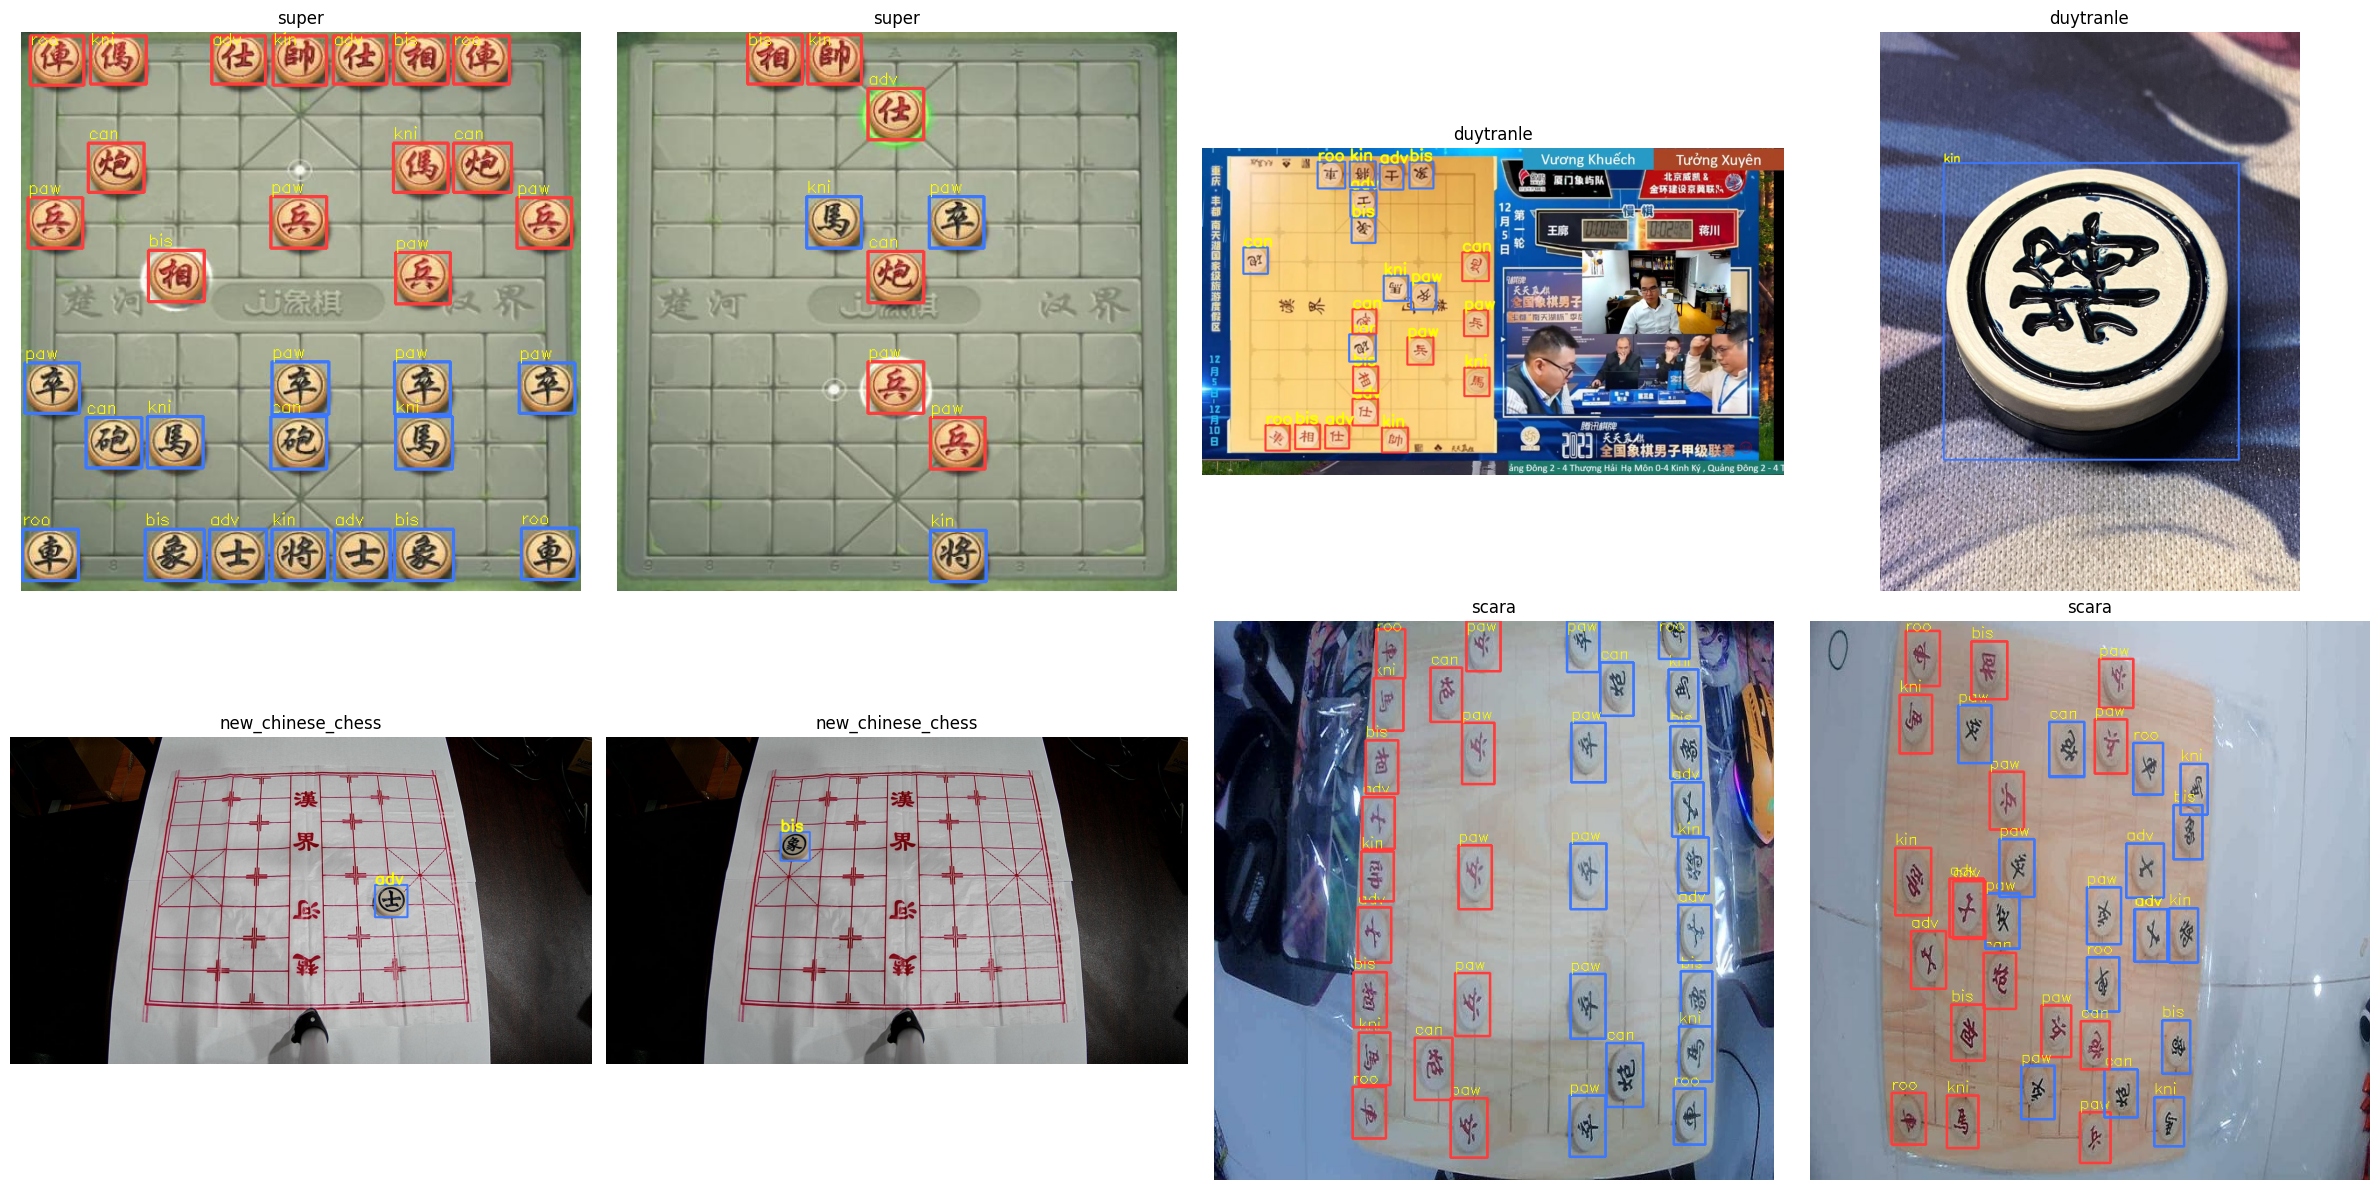

In [21]:
import cv2, matplotlib.pyplot as plt

# Lấy 2 ảnh train ngẫu nhiên (cố định seed) của mỗi bộ
picks = []
for dsn in ['super', 'duytranle', 'new_chinese_chess', 'scara']:
    sub = manifest[(manifest.dataset == dsn) & (manifest.split == 'train')]
    picks += sub.sample(2, random_state=7)[['file', 'dataset']].values.tolist()

fig, axes = plt.subplots(2, 4, figsize=(24, 12))

for ax, (f, dsn) in zip(axes.flatten(), picks):
    img = cv2.cvtColor(cv2.imread(f'{MERGED}/train/images/{f}'), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    thick, fs = max(2, W // 300), max(0.5, W / 1100)
    stem = os.path.splitext(f)[0]
    for line in open(f'{MERGED}/train/labels/{stem}.txt'):
        c, x, y, w, h = line.split()
        c, x, y, w, h = int(c), float(x), float(y), float(w), float(h)
        # đổi toạ độ YOLO chuẩn hoá (tâm, rộng, cao) -> pixel góc trên-trái / dưới-phải
        p1 = (int((x - w / 2) * W), int((y - h / 2) * H))
        p2 = (int((x + w / 2) * W), int((y + h / 2) * H))
        color = (255, 60, 60) if CLASSES[c].startswith('red') else (60, 120, 255)   # đỏ / xanh cho quân đen
        cv2.rectangle(img, p1, p2, color, thick)
        cv2.putText(img, CLASSES[c].split('_')[1][:3], (p1[0], max(p1[1] - 4, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 0), max(1, thick - 1))
    ax.imshow(img); ax.set_title(dsn); ax.axis('off')
plt.tight_layout(); plt.show()

### 🖼 Bảng 14 lớp: mỗi lớp một mẫu cắt từ tập train
Giúp người xem thấy rõ mô hình cần phân biệt những gì: cùng hình tròn, khác **chữ** và **màu**. Mỗi ô cắt quân cờ từ một ảnh ngẫu nhiên, tên tiếng Việt ở dưới.

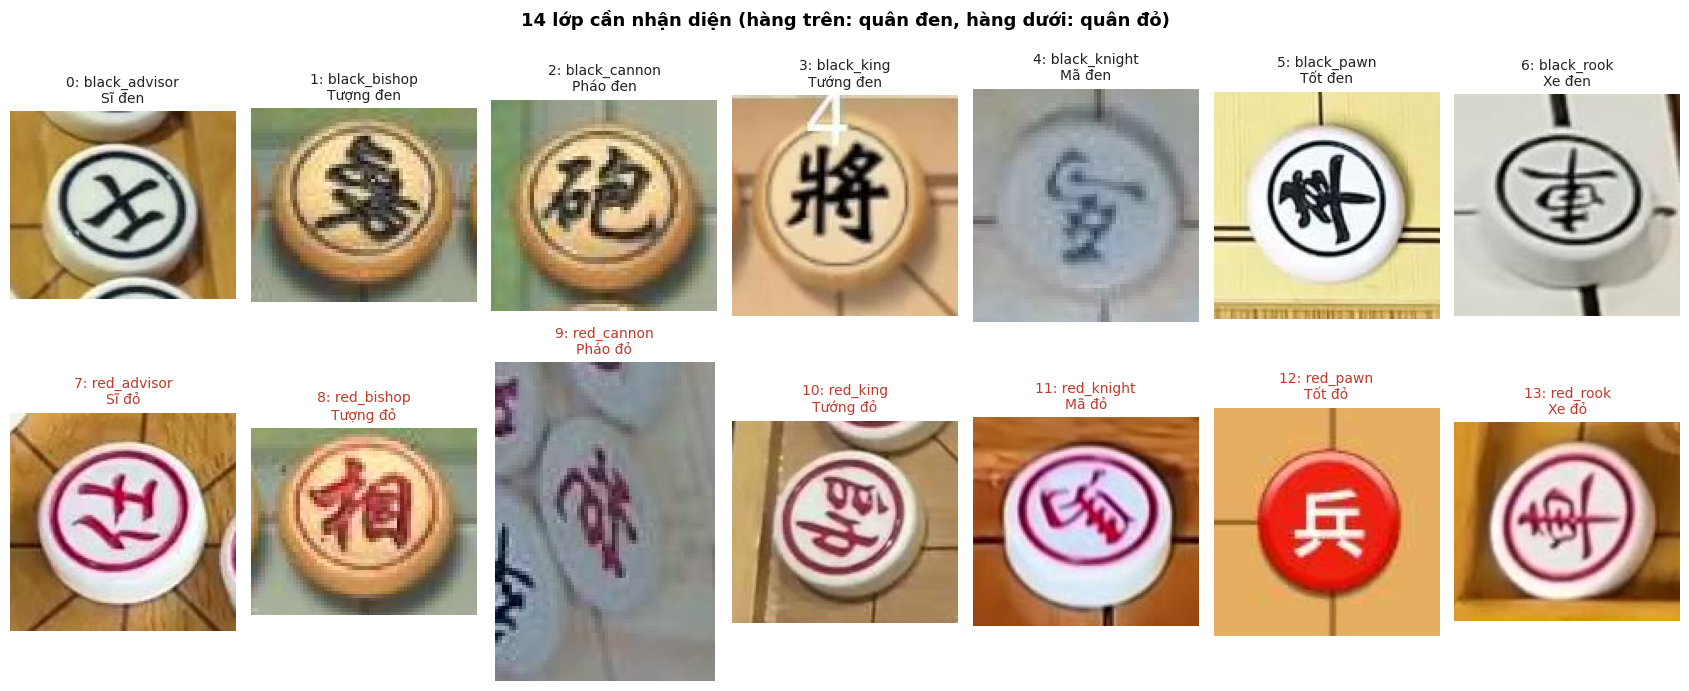

In [22]:
import random

VI_NAME = {'advisor': 'Sĩ', 'bishop': 'Tượng', 'cannon': 'Pháo', 'king': 'Tướng',
           'knight': 'Mã', 'pawn': 'Tốt', 'rook': 'Xe'}

def crop_example(cls_id, split='train', min_px=40, seed=0, max_try=400):
    # Tìm một box của lớp cls_id có cạnh >= min_px pixel, cắt kèm viền 15%
    rnd = random.Random(seed)
    files = manifest.loc[manifest.split == split, 'file'].tolist()
    for f in rnd.sample(files, min(max_try, len(files))):
        stem = os.path.splitext(f)[0]
        rows = [l.split() for l in open(f'{MERGED}/{split}/labels/{stem}.txt') if l.strip()]
        rows = [r for r in rows if int(r[0]) == cls_id]
        if not rows:
            continue
        img = cv2.imread(f'{MERGED}/{split}/images/{f}')
        H, W = img.shape[:2]
        _, x, y, w, h = map(float, rnd.choice(rows))
        if min(w * W, h * H) < min_px:
            continue
        pad = 0.15
        x0, x1 = int(max(0, (x - w / 2 - pad * w) * W)), int(min(W, (x + w / 2 + pad * w) * W))
        y0, y1 = int(max(0, (y - h / 2 - pad * h) * H)), int(min(H, (y + h / 2 + pad * h) * H))
        return cv2.cvtColor(img[y0:y1, x0:x1], cv2.COLOR_BGR2RGB)
    return None

fig, axes = plt.subplots(2, 7, figsize=(17, 7))
for cid, cname in enumerate(CLASSES):
    ax = axes[cid // 7][cid % 7]
    crop = crop_example(cid, seed=cid)
    if crop is not None:
        ax.imshow(crop)
    color, piece = cname.split('_')
    ax.set_title(f'{cid}: {cname}\n{VI_NAME[piece]} {"đỏ" if color == "red" else "đen"}',
                 fontsize=10, color='#C0392B' if color == 'red' else '#222')
    ax.axis('off')
fig.suptitle('14 lớp cần nhận diện (hàng trên: quân đen, hàng dưới: quân đỏ)', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
# 8. Kiểm tra với một ảnh bất kỳ trong tập test

Chọn **ngẫu nhiên một ảnh** trong tập test vừa tạo và kiểm tra trọn vẹn:
1. **Thông tin nguồn gốc:** thuộc bộ nào, tập gốc nào, nhóm nào.
2. **Kiểm tra tự động:** file nhãn tồn tại, class id hợp lệ (0–13), toạ độ nằm trong [0, 1], và **nhóm của ảnh không xuất hiện trong train/val** (không rò rỉ).
3. **Hiển thị:** ảnh gốc ↔ ảnh vẽ nhãn thật (ground truth) với tên lớp đầy đủ, kèm số quân mỗi lớp và kích thước box.

> Đặt `TEST_SEED = None` để mỗi lần chạy lấy một ảnh khác; đặt một số nguyên (vd `TEST_SEED = 3`) để lần nào cũng ra cùng một ảnh khi trình bày.

Ảnh       : super__remapped_66_jpg.rf.07420030b1899978279f338d49043621.jpg
Nguồn     : super | tập gốc: train | nhóm: 513 | số box: 16
  ✅ Có file nhãn và ít nhất 1 box
  ✅ Class id trong khoảng 0–13
  ✅ Toạ độ box nằm trong [0, 1]
  ✅ Nhóm của ảnh KHÔNG có trong train/val


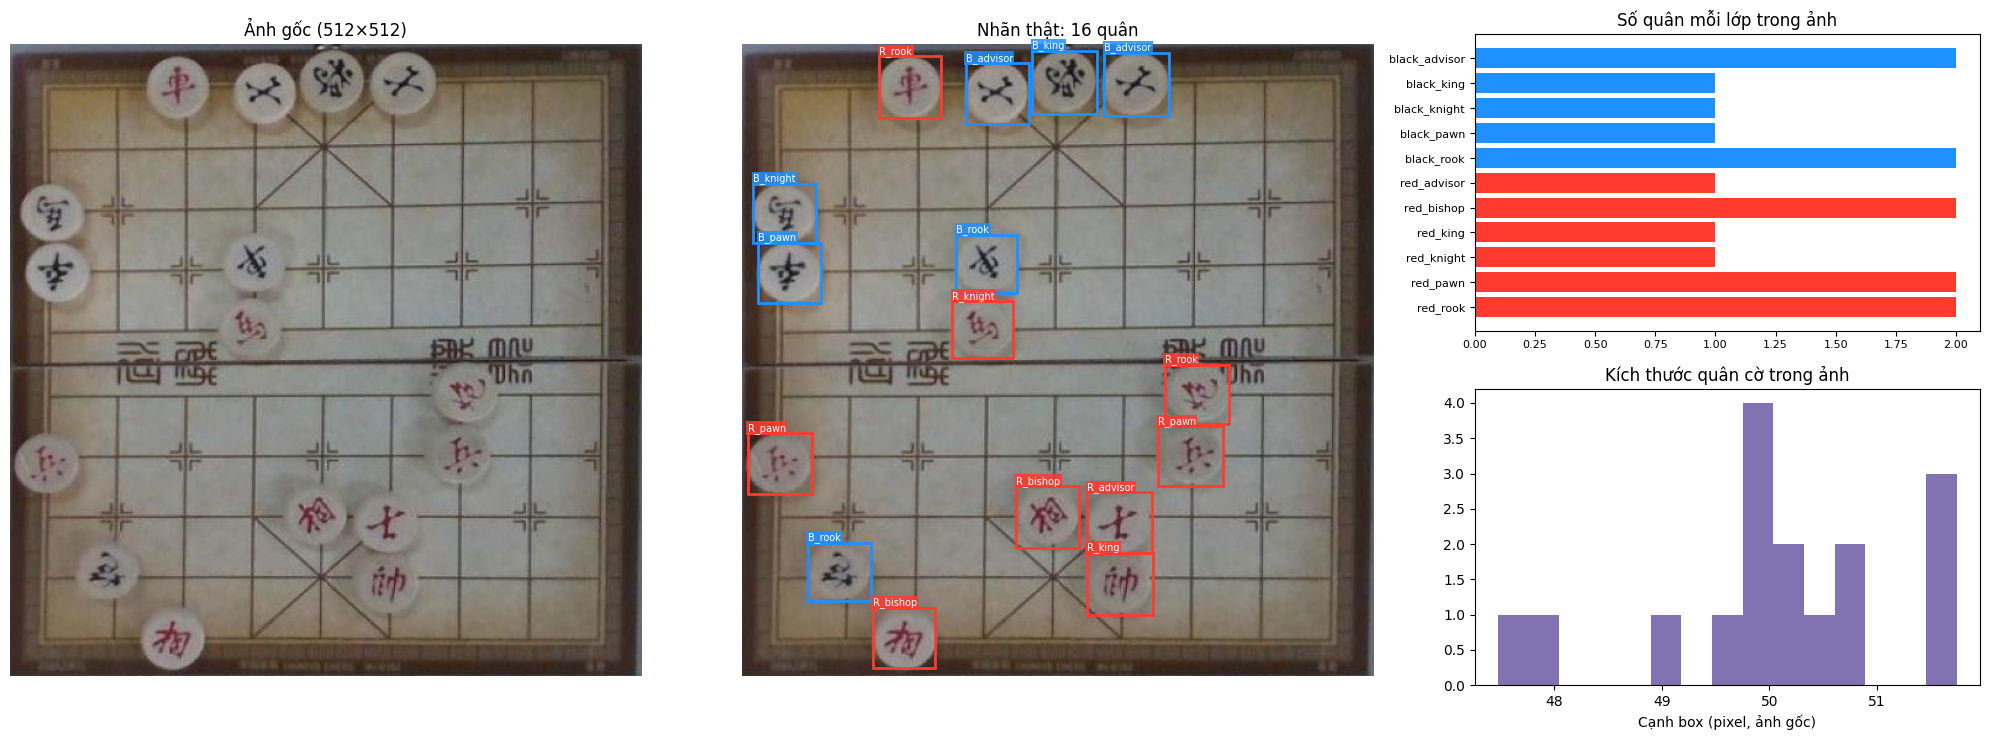

In [23]:
import random
import matplotlib.patches as mpatches

TEST_SEED = None          # None = ngẫu nhiên mỗi lần; số nguyên = cố định ảnh khi trình bày
SHORT = {c: c.replace('black_', 'B_').replace('red_', 'R_') for c in CLASSES}   # tên ngắn để vẽ

test_rows = manifest[manifest.split == 'test'].reset_index(drop=True)
row = test_rows.iloc[random.Random(TEST_SEED).randrange(len(test_rows))]
stem = os.path.splitext(row.file)[0]
img_path, lbl_path = f'{MERGED}/test/images/{row.file}', f'{MERGED}/test/labels/{stem}.txt'

# ── 1) Thông tin nguồn gốc
print('Ảnh       :', row.file)
print('Nguồn     :', row.dataset, '| tập gốc:', row.orig_split, '| nhóm:', row.group, '| số box:', row.n_box)

# ── 2) Kiểm tra tự động
gt = []   # (class_id, x, y, w, h) chuẩn hoá
assert os.path.exists(lbl_path), 'Thiếu file nhãn!'
for line in open(lbl_path):
    p = line.split()
    if p:
        c, x, y, w, h = int(p[0]), *map(float, p[1:])
        gt.append((c, x, y, w, h))
checks = {
    'Có file nhãn và ít nhất 1 box': len(gt) > 0,
    'Class id trong khoảng 0–13': all(0 <= c < len(CLASSES) for c, *_ in gt),
    'Toạ độ box nằm trong [0, 1]': all(0 <= x - w / 2 + 1e-6 and x + w / 2 <= 1 + 1e-6 and
                                      0 <= y - h / 2 + 1e-6 and y + h / 2 <= 1 + 1e-6 for _, x, y, w, h in gt),
    'Nhóm của ảnh KHÔNG có trong train/val': set(manifest.loc[manifest.group == row.group, 'split']) == {'test'},
}
for k, ok in checks.items():
    print(('  ✅ ' if ok else '  ❌ ') + k)

# ── 3) Hiển thị: ảnh gốc | ảnh có nhãn thật | thống kê
img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
H, W = img.shape[:2]
fig = plt.figure(figsize=(20, 7.5))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 0.8])
ax0, ax1 = fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[:, 1])
ax2, ax3 = fig.add_subplot(gs[0, 2]), fig.add_subplot(gs[1, 2])

ax0.imshow(img); ax0.set_title(f'Ảnh gốc ({W}×{H})'); ax0.axis('off')
ax1.imshow(img); ax1.set_title(f'Nhãn thật: {len(gt)} quân'); ax1.axis('off')
for c, x, y, w, h in gt:
    col = '#FF3B30' if CLASSES[c].startswith('red') else '#1E90FF'
    ax1.add_patch(mpatches.Rectangle(((x - w / 2) * W, (y - h / 2) * H), w * W, h * H, fill=False, ec=col, lw=2))
    ax1.text((x - w / 2) * W, (y - h / 2) * H - 2, SHORT[CLASSES[c]], color='white', fontsize=7,
             bbox=dict(fc=col, ec='none', pad=1, alpha=0.85))

cnt = Counter(CLASSES[c] for c, *_ in gt)
names_sorted = [c for c in CLASSES if c in cnt]
ax2.barh(names_sorted, [cnt[c] for c in names_sorted],
         color=['#FF3B30' if c.startswith('red') else '#1E90FF' for c in names_sorted])
ax2.invert_yaxis(); ax2.set_title('Số quân mỗi lớp trong ảnh'); ax2.tick_params(labelsize=8)

side = [np.sqrt(w * W * h * H) for _, _, _, w, h in gt]
ax3.hist(side, bins=15, color='#8172B2'); ax3.set_xlabel('Cạnh box (pixel, ảnh gốc)')
ax3.set_title('Kích thước quân cờ trong ảnh')
plt.tight_layout(); plt.show()

### (Tuỳ chọn) So sánh nhãn thật với dự đoán của mô hình trên chính ảnh đó
Nếu đã train xong (có file `best.pt` trên Drive), ô dưới chạy mô hình lên ảnh test vừa chọn và **đối chiếu từng quân**:
- 🟩 **TP** – đúng vị trí (IoU ≥ 0.5) và đúng lớp
- 🟥 **FP** – dự đoán thừa hoặc sai lớp
- 🟧 **FN** – quân có thật nhưng mô hình bỏ sót (khung đứt nét)

Nếu chưa có mô hình, ô sẽ bỏ qua.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


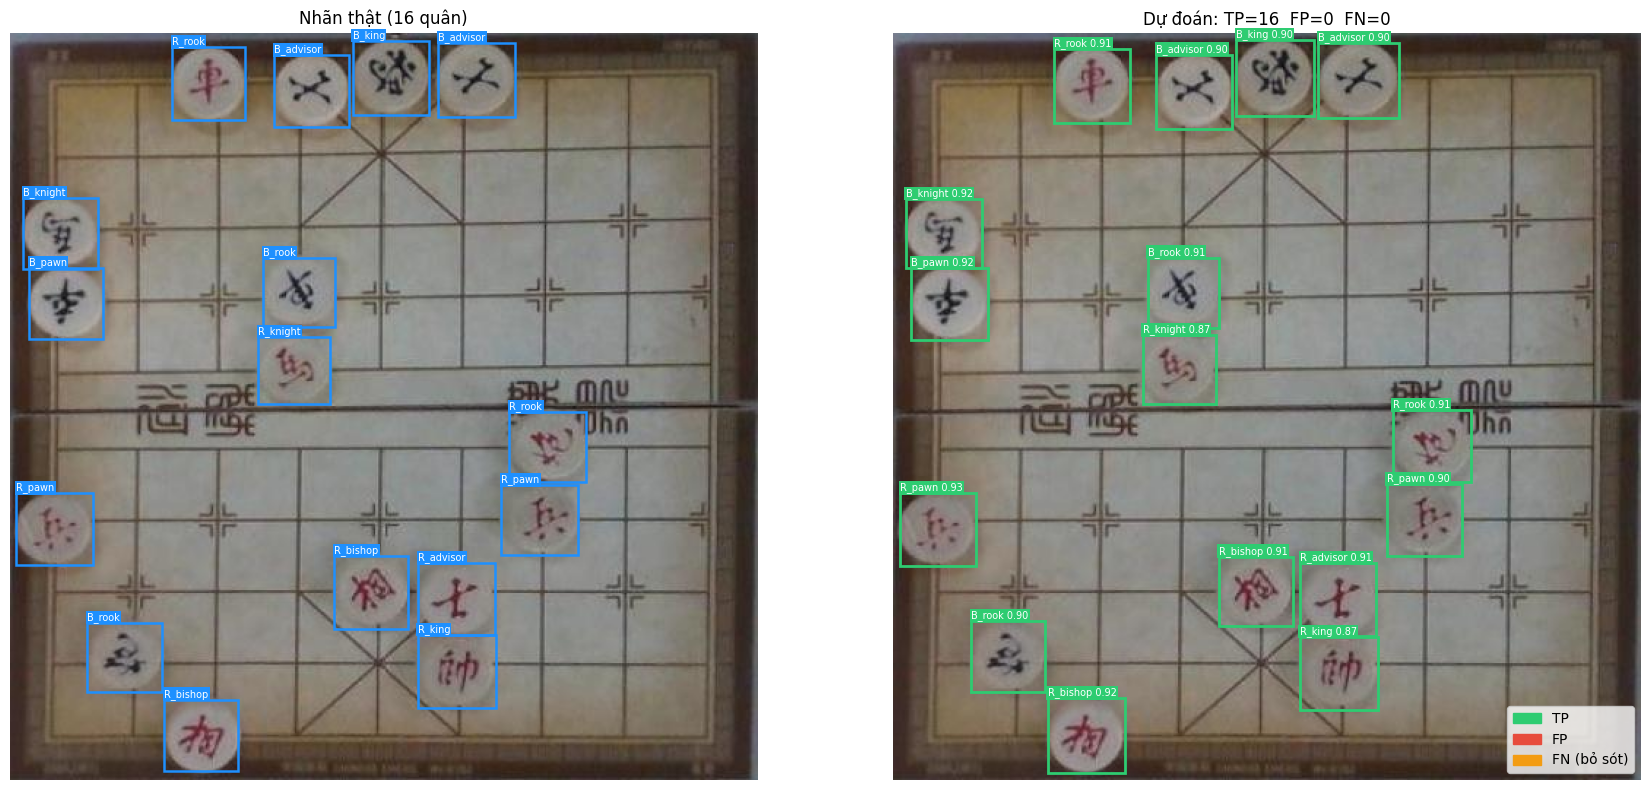

Trên ảnh này: precision = 1.000 | recall = 1.000 | thời gian suy luận = 10.9 ms


In [24]:
import subprocess, sys

MODEL_PATH = f'{BASE}/runs/yolo11n_640_rot/weights/best.pt'   # mô hình cuối cùng (sau fine-tune xoay)

def iou_xyxy(a, b):
    # IoU giữa 2 box [x0, y0, x1, y1]
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)

def match_boxes(gt_xyxy, gt_cls, pr_xyxy, pr_cls, pr_conf, thr=0.5):
    # Ghép tham lam theo độ tin cậy giảm dần: một dự đoán là TP nếu IoU >= thr với một GT cùng lớp chưa ghép
    used, tp = set(), []
    for i in np.argsort(-np.asarray(pr_conf)):
        best_j, best_iou = -1, thr
        for j in range(len(gt_xyxy)):
            if j in used or gt_cls[j] != pr_cls[i]:
                continue
            v = iou_xyxy(pr_xyxy[i], gt_xyxy[j])
            if v >= best_iou:
                best_j, best_iou = j, v
        if best_j >= 0:
            used.add(best_j); tp.append(i)
    fp = [i for i in range(len(pr_xyxy)) if i not in tp]
    fn = [j for j in range(len(gt_xyxy)) if j not in used]
    return tp, fp, fn

if not os.path.exists(MODEL_PATH):
    print('Chưa có mô hình tại', MODEL_PATH, '-> bỏ qua (chạy notebook train_yolo11.ipynb trước).')
else:
    try:
        from ultralytics import YOLO
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'], check=True)
        from ultralytics import YOLO
    det = YOLO(MODEL_PATH)
    r = det.predict(img_path, imgsz=640, conf=0.5, verbose=False)[0]
    pr_xyxy = r.boxes.xyxy.cpu().numpy(); pr_cls = r.boxes.cls.cpu().numpy().astype(int)
    pr_conf = r.boxes.conf.cpu().numpy()
    gt_xyxy = [((x - w / 2) * W, (y - h / 2) * H, (x + w / 2) * W, (y + h / 2) * H) for _, x, y, w, h in gt]
    gt_cls = [c for c, *_ in gt]
    tp, fp, fn = match_boxes(gt_xyxy, gt_cls, pr_xyxy, pr_cls, pr_conf)

    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    axes[0].imshow(img); axes[0].set_title(f'Nhãn thật ({len(gt)} quân)'); axes[0].axis('off')
    for (x0, y0, x1, y1), c in zip(gt_xyxy, gt_cls):
        axes[0].add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='#1E90FF', lw=1.8))
        axes[0].text(x0, y0 - 2, SHORT[CLASSES[c]], fontsize=7, color='white', bbox=dict(fc='#1E90FF', ec='none', pad=1))
    axes[1].imshow(img); axes[1].axis('off')
    for i, (x0, y0, x1, y1) in enumerate(pr_xyxy):
        col = '#2ECC71' if i in tp else '#E74C3C'
        axes[1].add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=col, lw=2))
        axes[1].text(x0, y0 - 2, f'{SHORT[CLASSES[pr_cls[i]]]} {pr_conf[i]:.2f}', fontsize=7, color='white',
                     bbox=dict(fc=col, ec='none', pad=1))
    for j in fn:
        x0, y0, x1, y1 = gt_xyxy[j]
        axes[1].add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='#F39C12', lw=2, ls='--'))
    axes[1].set_title(f'Dự đoán: TP={len(tp)}  FP={len(fp)}  FN={len(fn)}')
    axes[1].legend(handles=[mpatches.Patch(color='#2ECC71', label='TP'), mpatches.Patch(color='#E74C3C', label='FP'),
                            mpatches.Patch(color='#F39C12', label='FN (bỏ sót)')], loc='lower right')
    plt.tight_layout(); plt.show()
    prec = len(tp) / max(1, len(tp) + len(fp)); rec = len(tp) / max(1, len(gt))
    print(f'Trên ảnh này: precision = {prec:.3f} | recall = {rec:.3f} | thời gian suy luận = {r.speed["inference"]:.1f} ms')

---
# Tổng kết

| Hạng mục | Giá trị |
|---|---|
| Nguồn | 4 bộ Roboflow Universe (`super`, `scara`, `new_chinese_chess`, `duytranle`) |
| Số lớp | 14 (7 loại quân × 2 màu) |
| Ảnh sau làm sạch | **6 808** ảnh, **112 938** box |
| Chia tập (theo nhóm, không rò rỉ) | train **5 469** (80.3%) · val **675** (9.9%) · test **664** (9.8%) |
| Lớp ít nhất / nhiều nhất | `black_king` ≈ 4.4k box / `red_pawn` ≈ 15.8k box |
| Đầu ra | `MyDrive/datn/merged/merged_v1.zip` (kèm `data.yaml`, `manifest.csv`) |

**Những điểm đáng chú ý khi trình bày:**
1. Dữ liệu gộp từ nhiều nguồn → đa dạng bộ quân, ánh sáng, góc chụp.
2. Mọi định dạng nhãn (bbox, polygon, pose) được đưa về **bbox YOLO** với 14 tên lớp thống nhất.
3. Phát hiện cách chia gốc **bị rò rỉ** (191 nhóm) → chia lại theo nhóm bằng pHash + union-find + StratifiedGroupKFold.
4. Có kiểm tra tự động và kiểm tra bằng mắt trước khi train.

➡ **Bước tiếp theo:** `train_yolo11.ipynb` — huấn luyện YOLO11n trên `merged_v1`.